### Strathmore Institute of Mathematical Sciences | Master of Science in Data Science and Analytics
### DSA 8401 Applied Machine Learning | Capstone
#### 084045


#### Capstone Project: An End-to-End Behavioural Early-Warning Engine for Bank Account Dormancy and Disengagement Risk

**Dataset:** ai-lab/MBD-mini  
**Source:** Hugging Face 

### Imports

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose  import ColumnTransformer

from sklearn.preprocessing import (RobustScaler, OneHotEncoder)

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

print(f'Imports completed')

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
/opt/anaconda3/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Imports completed


In [3]:
# install hugging face package
%pip install -U datasets huggingface_hub pandas

Note: you may need to restart the kernel to use updated packages.


### Data Download

**Source:** [MBD-mini](https://huggingface.co/datasets/ai-lab/MBD-mini) (Sber AI Lab,
licence CC BY 4.0), a 10% client sample of the Multimodal Banking Dataset
([Mollaev et al., 2024](https://arxiv.org/abs/2409.17587)).

The repository holds four archives. Download detail, client_split, targets and ptls files:

| Archive | Contents|
|---|---|
| `detail.tar.gz` | Raw event tables: transactions, geo-activity, support dialogues|
| `client_split.tar.gz` | Client-to-fold assignment|
| `targets.tar.gz` | The authors' monthly product-purchase targets|
| `ptls.tar.gz` | Pre-aggregated sequences for one specific library|

In [4]:
# download MBD-mini file; target.tar.gz 
from huggingface_hub import hf_hub_download

targets_path = hf_hub_download(
    repo_id="ai-lab/MBD-mini",
    filename="targets.tar.gz",
    repo_type="dataset"
)

print(targets_path)

/Users/tintin/.cache/huggingface/hub/datasets--ai-lab--MBD-mini/snapshots/4b0d5b4c0b014e02af6c2e6b7b27851e6fb0d5c3/targets.tar.gz


In [5]:
# download  detail.tar.gz file
from huggingface_hub import hf_hub_download

detail_path = hf_hub_download(
    repo_id="ai-lab/MBD-mini",
    filename="detail.tar.gz",
    repo_type="dataset"
)

print(detail_path)

/Users/tintin/.cache/huggingface/hub/datasets--ai-lab--MBD-mini/snapshots/4b0d5b4c0b014e02af6c2e6b7b27851e6fb0d5c3/detail.tar.gz


In [6]:
# download  client_split.tar.gz file
from huggingface_hub import hf_hub_download

client_split_path = hf_hub_download(
    repo_id="ai-lab/MBD-mini",
    filename="client_split.tar.gz",
    repo_type="dataset"
)

print(client_split_path)

/Users/tintin/.cache/huggingface/hub/datasets--ai-lab--MBD-mini/snapshots/4b0d5b4c0b014e02af6c2e6b7b27851e6fb0d5c3/client_split.tar.gz


In [7]:
# download  ptls.tar.gz file
from huggingface_hub import hf_hub_download

ptls_path = hf_hub_download(
    repo_id="ai-lab/MBD-mini",
    filename="ptls.tar.gz",
    repo_type="dataset"
)

print(ptls_path)

/Users/tintin/.cache/huggingface/hub/datasets--ai-lab--MBD-mini/snapshots/4b0d5b4c0b014e02af6c2e6b7b27851e6fb0d5c3/ptls.tar.gz


In [8]:
import os

dataset_path = os.path.expanduser("~/Documents/School//School/MSc. DSA 4/DSA 8401 Applied Machine Learning/Capstone Project")

os.makedirs(dataset_path, exist_ok=True)

print(dataset_path)

/Users/tintin/Documents/School//School/MSc. DSA 4/DSA 8401 Applied Machine Learning/Capstone Project


In [9]:
dataset_path = (
    "/Users/tintin/.cache/huggingface/hub/"
    "datasets--ai-lab--MBD-mini/snapshots/"
    "4b0d5b4c0b014e02af6c2e6b7b27851e6fb0d5c3"
)

print(os.path.exists(dataset_path))

True


In [10]:
files = os.listdir(dataset_path)

for file in files:
    if file.endswith(".tar.gz"):
        file_path = os.path.join(dataset_path, file)

        size = os.path.getsize(file_path) / (1024**3)

        print(f"{file}: {size:.2f} GB")

targets.tar.gz: 0.01 GB
ptls.tar.gz: 1.30 GB
detail.tar.gz: 1.83 GB
client_split.tar.gz: 0.00 GB


In [11]:
# extracting all four archives
import tarfile

archives = [
    "targets.tar.gz",
    "client_split.tar.gz",
    "detail.tar.gz",
    "ptls.tar.gz"
]

for archive in archives:

    archive_path = os.path.join(dataset_path, archive)

    folder_name = archive.replace(".tar.gz", "")
    extract_path = os.path.join(dataset_path, folder_name)

    os.makedirs(extract_path, exist_ok=True)

    with tarfile.open(archive_path, "r:gz") as tar:
        tar.extractall(path=extract_path, filter="data")

    print(f"Successfully extracted: {archive}")

Successfully extracted: targets.tar.gz
Successfully extracted: client_split.tar.gz
Successfully extracted: detail.tar.gz
Successfully extracted: ptls.tar.gz


In [12]:
# inspection of extracted files
for folder in ["targets", "client_split", "detail", "ptls"]:

    folder_path = os.path.join(dataset_path, folder)

    print(f"\n{'='*50}")
    print(f"FOLDER: {folder}")
    print('='*50)

    for root, dirs, files in os.walk(folder_path):
        for file in files:
            file_path = os.path.join(root, file)

            size = os.path.getsize(file_path) / (1024**2)

            print(f"{file} | {size:.2f} MB")


FOLDER: targets
_SUCCESS | 0.00 MB
part-00083-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.04 MB
part-00036-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.03 MB
part-00042-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.02 MB
part-00063-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.03 MB
part-00017-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.03 MB
part-00068-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.02 MB
part-00021-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.03 MB
part-00055-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.02 MB
part-00074-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.02 MB
part-00000-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.02 MB
part-00049-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.03 MB
part-00045-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet | 0.02 MB
part-00031-44ca8b70-9d42-48f

In [14]:
# locate parquet files
from pathlib import Path

targets_dir = Path(dataset_path) / "targets"

parquet_files = list(targets_dir.rglob("*.parquet"))

print("Number of Parquet files:", len(parquet_files))

# Display the first 5 file paths
for file in parquet_files[:5]:
    print(file.relative_to(targets_dir))

Number of Parquet files: 435
targets/fold=0/part-00083-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet
targets/fold=0/part-00036-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet
targets/fold=0/part-00042-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet
targets/fold=0/part-00063-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet
targets/fold=0/part-00017-44ca8b70-9d42-48f7-9dec-0a7a012af308.c000.snappy.parquet


In [13]:
%pip install pyarrow

Note: you may need to restart the kernel to use updated packages.


In [15]:
import pyarrow.dataset as ds

In [ ]:
EXTRACTED = Path(dataset_path)

TABLES = {
    "client_split": EXTRACTED / "client_split" / "client_split",
    "trx": EXTRACTED / "detail" / "detail" / "trx",
    "geo": EXTRACTED / "detail" / "detail" / "geo",
    "dialog": EXTRACTED / "detail" / "detail" / "dialog",
    "targets": EXTRACTED / "targets" / "targets",
}

In [17]:
for name, path in TABLES.items():
    print(f"{name}: {'Found' if path.exists() else 'NOT FOUND'}")

client_split: Found
trx: Found
geo: Found
dialog: Found
targets: Found


In [18]:
datasets = {
    name: ds.dataset(path, format="parquet", partitioning="hive")
    for name, path in TABLES.items()
}

### Inventory: size, rows and columns

In [19]:
inventory = []

for name, dset in datasets.items():
    files = list(TABLES[name].rglob("*.parquet"))

    inventory.append({
        "table": name,
        "files": len(files),
        "size_MB": sum(f.stat().st_size for f in files) / 1e6,
        "rows": dset.count_rows(),
        "columns": len(dset.schema),
    })

inventory = pd.DataFrame(inventory).set_index("table")

inventory.style.format({
    "size_MB": "{:,.1f}",
    "rows": "{:,}",
})

,files,size_MB,rows,columns
table,,,,
client_split,1000,7.5,"100,224",2
trx,400,677.3,"38,764,930",15
geo,460,832.5,"66,295,724",6
dialog,415,673.9,"217,205",4
targets,435,11.5,"1,202,688",9


In [ ]:
# inspect tables schema; data types
for name, dset in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"TABLE: {name}")
    print(f"{'=' * 60}")
    print(dset.schema)


TABLE: client_split
client_id: string
fold: int32
-- schema metadata --
org.apache.spark.version: '3.2.1'
org.apache.spark.sql.parquet.row.metadata: '{"type":"struct","fields":[{"' + 66

TABLE: trx
client_id: string
event_time: timestamp[ns]
amount: float
event_type: int32
event_subtype: int32
currency: int32
src_type11: int32
src_type12: int32
dst_type11: int32
dst_type12: int32
src_type21: int32
src_type22: int32
src_type31: int32
src_type32: int32
fold: int32
-- schema metadata --
org.apache.spark.version: '3.2.1'
org.apache.spark.sql.parquet.row.metadata: '{"type":"struct","fields":[{"' + 960

TABLE: geo
client_id: string
event_time: timestamp[ns]
geohash_4: int32
geohash_5: int32
geohash_6: int32
fold: int32
-- schema metadata --
org.apache.spark.version: '3.2.1'
org.apache.spark.sql.parquet.row.metadata: '{"type":"struct","fields":[{"' + 341

TABLE: dialog
client_id: string
event_time: timestamp[ns]
embedding: list<element: float>
  child 0, element: float
fold: int32
-- schema 

In [ ]:
# read data
for name, dset in datasets.items():
    print(f"\nTABLE: {name}")
    display(dset.head(5).to_pandas())


TABLE: client_split


,client_id,fold
0,091d957b9e571dc1ddb66017f32202d3a4f48583b6399a...,0
1,1171cec680efbb4fd268a9ade0e94512c7a6f1e08a98a6...,0
2,127042b9a315782dfba125603f5173144f2b1e9b86b0bd...,0
3,14a3fab5925a8c9271ab9e16c25fedb47122095476a741...,0
4,2421da099471e3c4cca875717d19c6853a80930a01fad1...,0



TABLE: trx


,client_id,event_time,amount,event_type,event_subtype,currency,src_type11,src_type12,dst_type11,dst_type12,src_type21,src_type22,src_type31,src_type32,fold
0,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2022-10-26 13:58:59.938408,1.021543e+06,16,18,11,22,47,780,21619,21490,83,364,58,0
1,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2021-02-09 07:43:20.639579,3.007656e+05,1,12,11,4,958,306,26766,21490,83,364,58,0
2,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2022-10-22 09:12:06.614108,6.061549e+05,16,18,11,22,47,780,21619,21490,83,364,58,0
3,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2021-02-12 15:12:20.660481,8.032591e+04,1,12,11,4,958,306,26766,21490,83,364,58,0
4,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2022-10-08 06:52:28.877461,1.222866e+05,16,18,11,22,47,780,21619,21490,83,364,58,0



TABLE: geo


,client_id,event_time,geohash_4,geohash_5,geohash_6,fold
0,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-03-25 13:39:51.569288,41342,406579,1018528,0
1,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-06-11 07:21:32.505485,41342,406579,1018528,0
2,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-08-08 21:25:07.461323,41342,406579,1018528,0
3,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-07-23 11:32:03.433401,41342,406579,1018528,0
4,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-05-28 08:18:19.843885,41342,406579,1018528,0



TABLE: dialog


,client_id,event_time,embedding,fold
0,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2021-06-18 05:49:23.962741,"[0.393141, -0.036111, 0.311134, -0.197847, -0....",0
1,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2022-06-29 07:39:31.618769,"[0.302206, -0.381503, 0.472719, -0.284991, -0....",0
2,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2022-06-24 06:06:59.691367,"[0.570911, -0.395088, 0.546858, -0.413399, -0....",0
3,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2021-05-12 12:34:32.616245,"[0.232727, -0.284487, 0.584149, -0.524622, -0....",0
4,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2021-10-25 05:25:17.810891,"[0.316968, -0.149733, 0.426037, -0.395491, -0....",0



TABLE: targets


,client_id,mon,target_1,target_2,target_3,target_4,trans_count,diff_trans_date,fold
0,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-02-28,0,0,0,0,10,0,0
1,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-03-31,0,0,0,0,29,0,0
2,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-04-30,0,0,0,0,51,0,0
3,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-05-31,0,0,0,0,52,4,0
4,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-06-30,0,0,0,0,52,35,0


In [22]:
def peek(name: str, n: int = 5) -> pd.DataFrame:
    df = datasets[name].head(n).to_pandas()
    if "embedding" in df:  # 768 floats per row; show the length only
        df["embedding"] = df["embedding"].map(lambda v: f"<{len(v)} floats>")
    return df


print(datasets["trx"].schema.remove_metadata())
peek("trx")

client_id: string
event_time: timestamp[ns]
amount: float
event_type: int32
event_subtype: int32
currency: int32
src_type11: int32
src_type12: int32
dst_type11: int32
dst_type12: int32
src_type21: int32
src_type22: int32
src_type31: int32
src_type32: int32
fold: int32


,client_id,event_time,amount,event_type,event_subtype,currency,src_type11,src_type12,dst_type11,dst_type12,src_type21,src_type22,src_type31,src_type32,fold
0,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2022-10-26 13:58:59.938408,1.021543e+06,16,18,11,22,47,780,21619,21490,83,364,58,0
1,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2021-02-09 07:43:20.639579,3.007656e+05,1,12,11,4,958,306,26766,21490,83,364,58,0
2,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2022-10-22 09:12:06.614108,6.061549e+05,16,18,11,22,47,780,21619,21490,83,364,58,0
3,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2021-02-12 15:12:20.660481,8.032591e+04,1,12,11,4,958,306,26766,21490,83,364,58,0
4,01a1aca1531e0d86b605759fedd36e1855f41a8a6a49b4...,2022-10-08 06:52:28.877461,1.222866e+05,16,18,11,22,47,780,21619,21490,83,364,58,0


In [23]:
print(datasets["geo"].schema.remove_metadata())
peek("geo")

client_id: string
event_time: timestamp[ns]
geohash_4: int32
geohash_5: int32
geohash_6: int32
fold: int32


,client_id,event_time,geohash_4,geohash_5,geohash_6,fold
0,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-03-25 13:39:51.569288,41342,406579,1018528,0
1,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-06-11 07:21:32.505485,41342,406579,1018528,0
2,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-08-08 21:25:07.461323,41342,406579,1018528,0
3,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-07-23 11:32:03.433401,41342,406579,1018528,0
4,397d52b11ce72699a5482e5397f63a03af1636c85e9e61...,2022-05-28 08:18:19.843885,41342,406579,1018528,0


In [24]:
print(datasets["dialog"].schema.remove_metadata())
peek("dialog")

client_id: string
event_time: timestamp[ns]
embedding: list<element: float>
  child 0, element: float
fold: int32


,client_id,event_time,embedding,fold
0,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2021-06-18 05:49:23.962741,<768 floats>,0
1,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2022-06-29 07:39:31.618769,<768 floats>,0
2,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2022-06-24 06:06:59.691367,<768 floats>,0
3,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2021-05-12 12:34:32.616245,<768 floats>,0
4,5226901c78c655767ac2a075e6edca6b410624f0c9d2fd...,2021-10-25 05:25:17.810891,<768 floats>,0


In [25]:
print(datasets["targets"].schema.remove_metadata())
peek("targets")

client_id: string
mon: string
target_1: int32
target_2: int32
target_3: int32
target_4: int32
trans_count: int32
diff_trans_date: int32
fold: int32


,client_id,mon,target_1,target_2,target_3,target_4,trans_count,diff_trans_date,fold
0,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-02-28,0,0,0,0,10,0,0
1,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-03-31,0,0,0,0,29,0,0
2,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-04-30,0,0,0,0,51,0,0
3,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-05-31,0,0,0,0,52,4,0
4,00bd0ecf3d5a33aa8756097967d07797dca4c98de9b61c...,2022-06-30,0,0,0,0,52,35,0


In [26]:
print(datasets["client_split"].schema.remove_metadata())
peek("client_split")

client_id: string
fold: int32


,client_id,fold
0,091d957b9e571dc1ddb66017f32202d3a4f48583b6399a...,0
1,1171cec680efbb4fd268a9ade0e94512c7a6f1e08a98a6...,0
2,127042b9a315782dfba125603f5173144f2b1e9b86b0bd...,0
3,14a3fab5925a8c9271ab9e16c25fedb47122095476a741...,0
4,2421da099471e3c4cca875717d19c6853a80930a01fad1...,0


### Time span of each table

In [28]:
import pyarrow.compute as pc

spans = []
for name in ["trx", "geo", "dialog"]:
    lo = hi = None
    for batch in datasets[name].to_batches(columns=["event_time"], batch_size=2_000_000):
        mm = pc.min_max(batch.column(0))
        lo = mm["min"].as_py() if lo is None else min(lo, mm["min"].as_py())
        hi = mm["max"].as_py() if hi is None else max(hi, mm["max"].as_py())
    spans.append({"table": name, "first_event": lo, "last_event": hi})

months = datasets["targets"].to_table(columns=["mon"]).column(0)
spans.append({"table": "targets (mon)", "first_event": pc.min(months).as_py(), "last_event": pc.max(months).as_py()})
pd.DataFrame(spans).set_index("table")

,first_event,last_event
table,,
trx,2020-12-31 21:00:02.169545,2022-12-31 20:59:58.460193
geo,2021-12-11 19:27:07.507106,2022-12-31 20:59:58.725788
dialog,2021-02-10 09:36:07.022271,2022-12-31 20:25:11.730797
targets (mon),2022-02-28,2023-01-31


- **Transactions span 24 months** (January 2021 to December 2022). The dataset card
  says 12 months, which describes the `targets` table, not the event tables.
- **Geo data starts only in December 2021**, so geo features can exist only for scoring
  dates in 2022.

### Which clients appear in which table?

In [29]:
def unique_clients(dset) -> set:
    # Batch by batch: geo alone has 66M rows, and loading its client_id column
    # at once needs more memory than a typical laptop has.
    seen = set()
    for batch in dset.to_batches(columns=["client_id"], batch_size=1_000_000):
        seen.update(pc.unique(batch.column(0)).to_pylist())
    return seen


clients = {name: unique_clients(dset) for name, dset in datasets.items()}
all_clients = clients["client_split"]

coverage = pd.DataFrame({
    "clients": {n: len(c) for n, c in clients.items()},
    "share_of_all_clients": {n: len(c & all_clients) / len(all_clients) for n, c in clients.items()},
    "not_in_client_split": {n: len(c - all_clients) for n, c in clients.items()},
})
coverage.style.format({"clients": "{:,}", "share_of_all_clients": "{:.1%}", "not_in_client_split": "{:,}"})

,clients,share_of_all_clients,not_in_client_split
client_split,"100,224",100.0%,0
trx,"98,721",98.5%,0
geo,"72,573",72.4%,0
dialog,"46,320",46.2%,0
targets,"100,224",100.0%,0


In [30]:
no_trx = all_clients - clients["trx"]
print(f"Clients with no transactions at all: {len(no_trx):,}")
print(f"Clients with transactions but no geo: {len(clients['trx'] - clients['geo']):,}")
print(f"Clients with transactions but no dialogue: {len(clients['trx'] - clients['dialog']):,}")

Clients with no transactions at all: 1,503
Clients with transactions but no geo: 27,074
Clients with transactions but no dialogue: 52,715


### Summary

| | |
|---|---|
| Population | 100,224 corporate clients (`client_split`) |
| Core table | `trx`: 38.8M transactions, 24 months |
| Optional sources | `geo` (2022 only, ~73% of clients), `dialog` (~46% of clients) |
| Not used as a label | `targets` (product purchases, a different task) |

- Dormancy is not given; we will **derive it from `trx`** (no transaction for N days).
- Clients with no transactions can never "become" dormant, so they leave the population.
- Missing `geo` or `dialog` for a client is normal (a missing *modality*), not a data error.

### Data preparation and cleaning

The transaction table has 38.8 million rows. Before choosing a tool, estimate what pandas would need by 
loading one million rows and scaling up.

In [33]:
TRX = EXTRACTED / "detail" / "detail" / "trx"
GEO = EXTRACTED / "detail" / "detail" / "geo"
DIALOG = EXTRACTED / "detail" / "detail" / "dialog"
SPLIT = EXTRACTED / "client_split" / "client_split"

In [34]:
sample = ds.dataset(TRX, format="parquet", partitioning="hive").head(1_000_000).to_pandas()
per_million = sample.memory_usage(deep=True).sum() / 1e9
print(f"pandas memory for 1M rows: {per_million:.2f} GB")
print(f"estimated for all 38.8M rows: {per_million * 38.8:.1f} GB")
del sample

pandas memory for 1M rows: 0.17 GB
estimated for all 38.8M rows: 6.5 GB


The notebook will use **Polars lazy queries**: each query is planned first and then run
in streaming batches, so the full table never sits in memory. Small results (counts,
summaries) are converted to pandas for display and plotting. Cleaning also replaces the
string `client_id` with a compact integer `client_key`.

In [35]:
!pip install polars

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 911.5/911.5 kB 5.6 MB/s eta 0:00:00-:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 MB 18.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [polars]2m1/2 [polars]


In [36]:
import polars as pl

In [37]:
trx = pl.scan_parquet(TRX / "**" / "*.parquet", hive_partitioning=True)
geo = pl.scan_parquet(GEO / "**" / "*.parquet", hive_partitioning=True)
dialog = pl.scan_parquet(DIALOG / "**" / "*.parquet", hive_partitioning=True)
split = pl.read_parquet(SPLIT / "**" / "*.parquet", hive_partitioning=True)


def run(lf: pl.LazyFrame) -> pl.DataFrame:
    # Execute a lazy query with the streaming engine
    return lf.collect(engine="streaming")


n_rows_raw = run(trx.select(pl.len())).item()
print(f"trx rows: {n_rows_raw:,}")
print(f"clients in client_split: {split.height:,}")

trx rows: 38,764,930
clients in client_split: 100,224


### Value Types

In [38]:
schema = trx.collect_schema()
pd.DataFrame({"dtype": [str(t) for t in schema.values()]}, index=list(schema.keys()))

,dtype
client_id,String
event_time,"Datetime(time_unit='ns', time_zone=None)"
amount,Float32
event_type,Int32
event_subtype,Int32
currency,Int32
src_type11,Int32
src_type12,Int32
dst_type11,Int32
dst_type12,Int32


In [39]:
# Client lookup table: one integer key per client
client_map = (
    split.sort("client_id")
    .with_row_index("client_key")
    .with_columns(pl.col("client_key").cast(pl.Int32))
    .select("client_key", "client_id", "fold")
)
print(f"{client_map.height:,} clients, keys 0 to {client_map['client_key'].max():,}")
print(f"duplicate client_ids in client_split: {split['client_id'].is_duplicated().sum()}")
client_map.head()

100,224 clients, keys 0 to 100,223
duplicate client_ids in client_split: 0


client_key,client_id,fold
i32,str,i64
0,"""000032cc38caee45fe031778bcf6af…",2
1,"""00005e39da5fb5968996cd49130281…",4
2,"""00012766278a7b25ddd3d6de329a44…",3
3,"""0001edbc5ab720f70a615ed9e8429d…",4
4,"""0002ddd816198d32474486d54f4bfe…",4


### Duplicates

In [40]:
n_unique_rows = run(trx.unique().select(pl.len())).item()
print(f"exact duplicate rows: {n_rows_raw - n_unique_rows:,}")

exact duplicate rows: 0


No two rows are identical across all columns. 

### Missing Values

In [41]:
nulls = run(trx.null_count()).to_pandas().T.rename(columns={0: "null_count"})
nulls["null_pct"] = nulls["null_count"] / n_rows_raw * 100
nulls.sort_values("null_count", ascending=False)

,null_count,null_pct
dst_type11,243824,0.628981
dst_type12,243824,0.628981
src_type11,217361,0.560716
src_type12,217361,0.560716
src_type31,78996,0.203782
src_type32,78996,0.203782
src_type21,42293,0.109101
src_type22,42293,0.109101
currency,118,0.000304
client_id,0,0.000000


In [42]:
# Which columns have missing values and are they missing on the same rows?
nullable = nulls.index[nulls["null_count"] > 0].tolist()
print("columns with missing values:", nullable)
together = run(trx.select(
    pl.any_horizontal([pl.col(c).is_null() for c in nullable]).sum().alias("any_null"),
    pl.all_horizontal([pl.col(c).is_null() for c in nullable]).sum().alias("all_null"),
)).to_pandas()
together

columns with missing values: ['currency', 'src_type11', 'src_type12', 'dst_type11', 'dst_type12', 'src_type21', 'src_type22', 'src_type31', 'src_type32']


,any_null,all_null
0,342181,0


In [43]:
# Which transaction types have the missing values?
by_type = run(
    trx.group_by("event_type").agg(
        pl.len().alias("rows"),
        pl.any_horizontal([pl.col(c).is_null() for c in nullable]).mean().alias("null_share"),
    ).sort("rows", descending=True)
).to_pandas()
by_type[by_type["null_share"] > 0].sort_values("null_share", ascending=False).head(10)

,event_type,rows,null_share
47,53,3648,0.734649
9,48,500698,0.366932
41,47,12153,0.263474
35,21,20046,0.037863
14,4,212882,0.024986
30,25,41042,0.013937
12,19,265519,0.011769
1,46,5594429,0.011582
28,16,42500,0.009435
16,6,185591,0.007145


**Result.** Nine columns have missing values, all of them category codes: the four
`src/dst_type1*` columns (0.56 to 0.63% of rows), the four `src_type2*/3*` columns
(0.11 to 0.20%), and `currency` (118 rows).

The gaps are concentrated in a few transaction types: type 53 is missing these
attributes on 73% of its rows, type 48 on 37%. That pattern suggests the attributes
do not apply to those transactions (for example, no counterparty), rather than
being lost at random.

**Decision.** Fill every missing code with a new code, **-1 = "unknown / not
applicable"**. All real codes are 1 or higher, so -1 cannot clash. No rows are dropped: every transaction still counts as activity,
which is what dormancy is about.

### Inconsistent data

#### Time

In [44]:
local = trx.with_columns((pl.col("event_time") + pl.duration(hours=3)).alias("t_local"))
bounds = run(local.select(pl.col("t_local").min().alias("first"), pl.col("t_local").max().alias("last")))
bounds

first,last
datetime[μs],datetime[μs]
2021-01-01 00:00:02.169545,2022-12-31 23:59:58.460193


Convert every timestamp to bank-local time (UTC+3). Without this, about
2,500 transactions would fall in "December 2020", and every daily and monthly count
near a midnight boundary would be slightly wrong.

#### Amounts

In [45]:
amount_checks = run(trx.select(
    (pl.col("amount") <= 0).sum().alias("zero_or_negative"),
    pl.col("amount").is_nan().sum().alias("nan"),
    (pl.col("amount") < 1).sum().alias("below_1"),
    pl.col("amount").min().alias("min"),
    pl.col("amount").max().alias("max"),
)).to_pandas()
amount_checks

,zero_or_negative,nan,below_1,min,max
0,0,0,131781,0.000003,1.370187e+12


No zero, negative or missing amounts. About 132,000 transactions (0.34%) are below 1
unit; these are plausibly fees or an effect of anonymised scaling and are kept. The
largest amount is about 1.4 trillion units, examined in section 6.

#### Currency

In [46]:
currency = run(
    trx.group_by("currency").agg(
        pl.len().alias("rows"),
        pl.col("client_id").n_unique().alias("clients"),
        pl.col("amount").median().alias("median_amount"),
    ).sort("rows", descending=True)
).to_pandas()
currency["share_of_rows"] = currency["rows"] / currency["rows"].sum()
currency

,currency,rows,clients,median_amount,share_of_rows
0,11.0,38724240,98721,1.802502e+04,9.989503e-01
1,3.0,20324,636,8.939498e+04,5.242883e-04
2,15.0,16041,716,4.059371e+05,4.138019e-04
3,4.0,3128,178,1.238560e+04,8.069149e-05
4,17.0,446,27,1.276568e+04,1.150524e-05
5,10.0,199,22,1.437745e+04,5.133506e-06
6,8.0,174,15,7.074836e+03,4.488593e-06
7,1.0,159,5,1.153735e+04,4.101645e-06
8,NaN,118,8,7.449037e+04,3.043988e-06
9,6.0,82,10,5.038098e+05,2.115314e-06


Currency code 11 carries 99.9% of transactions and is used by every
client. Twelve other codes share the
remaining 0.1%, and 118 rows have no currency.

#### Category codes: is each subtype inside one type?

In [47]:
nesting = run(
    trx.group_by("event_subtype").agg(pl.col("event_type").n_unique().alias("types_per_subtype"))
)
print(f"distinct event_type: {run(trx.select(pl.col('event_type').n_unique())).item()}")
print(f"distinct event_subtype: {nesting.height}")
print(f"subtypes used under more than one type: {(nesting['types_per_subtype'] > 1).sum()}")

distinct event_type: 55
distinct event_subtype: 60
subtypes used under more than one type: 57


Almost every subtype appears under several types, so `event_subtype` is **not** a
child of `event_type`; it is a separate dimension. Both are kept as independent codes.

#### Do clients and folds agree across tables?

In [48]:
trx_clients = run(trx.group_by("client_id").agg(pl.col("fold").first().alias("fold_trx")))
check = trx_clients.join(client_map, on="client_id", how="left")
print(f"clients in trx: {trx_clients.height:,}")
print(f"clients in trx but not in client_split: {check['client_key'].is_null().sum():,}")
print(f"clients whose fold differs between trx and client_split: {(check['fold_trx'] != check['fold']).sum():,}")
print(f"clients in client_split with no transactions: {client_map.height - trx_clients.height:,}")

clients in trx: 98,721
clients in trx but not in client_split: 0
clients whose fold differs between trx and client_split: 0
clients in client_split with no transactions: 1,503


Every transaction belongs to a known client, and folds agree between tables. The 1,503
clients with no transactions at all are kept in the client table but **excluded from
the modelling population**: a client who never transacted cannot "become" dormant.

### Data Distribution

In [49]:
q = [0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1]
amount_q = run(trx.select([pl.col("amount").quantile(x).alias(f"{x:.0%}") for x in q])).to_pandas().T
amount_q.columns = ["amount"]
amount_q

,amount
0%,3.021821e-06
1%,6.385846e+00
5%,7.725962e+01
25%,2.453869e+03
50%,1.803584e+04
75%,9.475955e+04
95%,9.048114e+05
99%,5.377146e+06
100%,1.370187e+12


### Data Cleaning

In [53]:
LOCAL_OFFSET = pl.duration(hours=3)          # UTC -> bank-local time (UTC+3)
UNKNOWN_CODE = -1                            # fill for missing category codes (all real codes are >= 1)
CODE_COLS = ["event_type", "event_subtype", "currency", "src_type11", "src_type12",
             "dst_type11", "dst_type12", "src_type21", "src_type22", "src_type31", "src_type32"]

trx_clean = (
    trx
    .join(client_map.lazy().select("client_id", "client_key"), on="client_id", how="inner")
    .with_columns(
        (pl.col("event_time") + LOCAL_OFFSET).alias("event_time_local"),
        pl.col(CODE_COLS).fill_null(UNKNOWN_CODE),
        pl.col("amount").log1p().cast(pl.Float32).alias("log_amount"),
    )
    .select(["client_key", "event_time_local", "amount", "log_amount", *CODE_COLS])
    .sort("client_key", "event_time_local")
)

OUT_TRX = "trx_clean.parquet"
trx_clean.sink_parquet(OUT_TRX, compression="zstd", row_group_size=1_000_000)

In [55]:
geo_checks = run(geo.select(
    pl.len().alias("rows"),
    pl.all_horizontal(pl.all().is_not_null()).not_().sum().alias("rows_with_nulls"),
))
geo_dups = run(geo.group_by("client_id", "event_time", "geohash_6").len().filter(pl.col("len") > 1).select(pl.col("len").sum() - pl.len())).item()
print(geo_checks)
print(f"geo exact duplicate rows (client, time, geohash_6): {geo_dups:,}")

geo_clean = (
    geo
    .join(client_map.lazy().select("client_id", "client_key"), on="client_id", how="inner")
    .with_columns((pl.col("event_time") + LOCAL_OFFSET).alias("event_time_local"))
    .select("client_key", "event_time_local", "geohash_4", "geohash_5", "geohash_6")
)
OUT_GEO =  "geo_clean.parquet"
geo_clean.sink_parquet(OUT_GEO, compression="zstd", row_group_size=1_000_000)
# print(f"wrote {OUT_GEO.name}: {OUT_GEO.stat().st_size / 1e6:,.0f} MB")

shape: (1, 2)
┌──────────┬─────────────────┐
│ rows     ┆ rows_with_nulls │
│ ---      ┆ ---             │
│ u32      ┆ u32             │
╞══════════╪═════════════════╡
│ 66295724 ┆ 0               │
└──────────┴─────────────────┘
geo exact duplicate rows (client, time, geohash_6): 0


In [57]:
dlg = dialog.collect()
emb_len = dlg["embedding"].list.len()
print(f"dialog rows: {dlg.height:,}")
print(f"embedding lengths: {sorted(emb_len.unique().to_list())}")
print(f"embeddings containing NaN: {dlg['embedding'].list.eval(pl.element().is_nan().any()).explode().sum():,}")
print(f"duplicate (client, time) rows: {dlg.select(pl.struct('client_id', 'event_time').is_duplicated().sum()).item():,}")

dialog_clean = (
    dlg.join(client_map.select("client_id", "client_key"), on="client_id", how="inner")
    .with_columns(
        (pl.col("event_time") + LOCAL_OFFSET).alias("event_time_local"),
        pl.col("embedding").cast(pl.Array(pl.Float32, 768)),
    )
    .select("client_key", "event_time_local", "embedding")
    .sort("client_key", "event_time_local")
)
OUT_DIALOG = "dialog_clean.parquet"
dialog_clean.write_parquet(OUT_DIALOG, compression="zstd")
# print(f"wrote {OUT_DIALOG.name}: {OUT_DIALOG.stat().st_size / 1e6:,.0f} MB")
del dlg, dialog_clean

dialog rows: 217,205
embedding lengths: [768]
embeddings containing NaN: 0
duplicate (client, time) rows: 0


In [58]:
trx_out = pl.scan_parquet(OUT_TRX)
activity = run(trx_out.group_by("client_key").agg(
    pl.len().alias("n_trx"),
    pl.col("event_time_local").min().alias("first_trx"),
    pl.col("event_time_local").max().alias("last_trx"),
))
geo_keys = run(pl.scan_parquet(OUT_GEO).select(pl.col("client_key").unique()))["client_key"]
dialog_keys = pl.read_parquet(OUT_DIALOG, columns=["client_key"])["client_key"].unique()

clients = (
    client_map
    .join(activity, on="client_key", how="left")
    .with_columns(
        pl.col("n_trx").fill_null(0),
        pl.col("client_key").is_in(geo_keys.implode()).alias("has_geo"),
        pl.col("client_key").is_in(dialog_keys.implode()).alias("has_dialog"),
    )
    .with_columns((pl.col("n_trx") > 0).alias("in_population"))
)
OUT_CLIENTS = "clients.parquet"
clients.write_parquet(OUT_CLIENTS)
# print(f"wrote {OUT_CLIENTS.name}: {clients.height:,} clients")
clients.head().to_pandas()

,client_key,client_id,fold,n_trx,first_trx,last_trx,has_geo,has_dialog,in_population
0,0,000032cc38caee45fe031778bcf6af05aa2aabe476acb8...,2,344,2021-09-16 13:51:50.458732,2022-12-31 15:32:37.174632,True,True,True
1,1,00005e39da5fb5968996cd49130281c8bd074a42e0e17a...,4,13,2022-08-10 11:15:44.567628,2022-11-28 01:21:15.006878,False,True,True
2,2,00012766278a7b25ddd3d6de329a44dec4c278d5807fae...,3,19,2022-09-04 15:59:34.096437,2022-10-12 12:56:11.991623,False,False,True
3,3,0001edbc5ab720f70a615ed9e8429df9b6c3f3c3999a51...,4,315,2021-01-27 10:02:38.926094,2022-12-26 09:05:13.817154,True,False,True
4,4,0002ddd816198d32474486d54f4bfe4f7b361119b5dc45...,4,641,2021-01-01 07:24:53.293748,2022-12-27 10:54:52.099492,True,False,True


### Validate the outputs

In [59]:
WINDOW_START, WINDOW_END = pl.datetime(2021, 1, 1), pl.datetime(2023, 1, 1)

validation = run(trx_out.select(
    pl.len().alias("rows"),
    pl.col("client_key").n_unique().alias("clients"),
    pl.sum_horizontal(pl.all().null_count()).alias("nulls"),
    ((pl.col("event_time_local") < WINDOW_START) | (pl.col("event_time_local") >= WINDOW_END)).sum().alias("outside_window"),
    pl.col("log_amount").is_nan().sum().alias("nan_log_amount"),
)).to_pandas()
validation

,rows,clients,nulls,outside_window,nan_log_amount
0,38764930,98721,0,0,0


In [60]:
row = validation.iloc[0]
assert row["rows"] == n_rows_raw, "row count changed"
assert row["nulls"] == 0, "nulls remain"
assert row["outside_window"] == 0, "events outside Jan 2021 - Dec 2022 local time"
assert row["nan_log_amount"] == 0
assert clients["in_population"].sum() == row["clients"]
print("All checks passed.")

All checks passed.


In [61]:
cleaning_log = pd.DataFrame([
    ["Raw transactions", f"{n_rows_raw:,}", "38.8M rows, 98,721 clients"],
    ["Exact duplicates removed", "0", "none found"],
    ["Same-timestamp rows", "kept", "1 pair, two genuine transactions"],
    ["Missing category codes", "filled with -1", "9 code columns, at most 0.63% per column"],
    ["Non-domestic currency", "kept, flagged by code", "0.1% of rows; excluded from amount features later"],
    ["Time zone", "UTC -> UTC+3", "all events now inside Jan 2021 - Dec 2022"],
    ["Amount outliers", "kept", "log_amount added instead of capping"],
    ["client_id", "-> client_key (int32)", "lookup in clients.parquet"],
    ["Clients with no transactions", f"{(~clients['in_population']).sum():,}", "flagged, excluded from population"],
], columns=["Step", "Result", "Note"])
cleaning_log

,Step,Result,Note
0,Raw transactions,"38,764,930","38.8M rows, 98,721 clients"
1,Exact duplicates removed,0,none found
2,Same-timestamp rows,kept,"1 pair, two genuine transactions"
3,Missing category codes,filled with -1,"9 code columns, at most 0.63% per column"
4,Non-domestic currency,"kept, flagged by code",0.1% of rows; excluded from amount features later
5,Time zone,UTC -> UTC+3,all events now inside Jan 2021 - Dec 2022
6,Amount outliers,kept,log_amount added instead of capping
7,client_id,-> client_key (int32),lookup in clients.parquet
8,Clients with no transactions,"1,503","flagged, excluded from population"


### Summary

| Check | Finding | Action |
|---|---|---|
| Value types | Codes stored as integers; `client_id` is a 64-char string | Integer `client_key` |
| Duplicates | None exact; one same-timestamp pair, genuinely different | Nothing removed |
| Missing values | 9 code columns, ≤ 0.63% each, tied to specific transaction types | Code -1 = not applicable |
| Time zone | Stored in UTC; bank runs on UTC+3 | Shifted to local time |
| Currency | 99.9% domestic (code 11) | Amount features on code 11 only |
| Amounts | No invalid values; heavy right skew | Kept; `log_amount` added |
| Clients | 1,503 with no transactions | Excluded from population |

**Outputs in `data/interim/`**

| File | Rows | Contents |
|---|---|---|
| `trx_clean.parquet` | 38,764,930 | Transactions in local time, sorted by client and time |
| `geo_clean.parquet` | 66,295,724 | Geo events in local time |
| `dialog_clean.parquet` | 217,205 | Support-dialogue embeddings (768 floats) |
| `clients.parquet` | 100,224 | One row per client: activity span, sources, population flag |

No rows were dropped from any table; every change is a type, time-zone or fill fix.

### Exploratory Data Analysis

In [66]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
INTERIM = ROOT

In [68]:
from datetime import date, timedelta

In [69]:
def run(lf: pl.LazyFrame) -> pl.DataFrame:
    return lf.collect(engine="streaming")


trx = pl.scan_parquet(INTERIM / "trx_clean.parquet")
clients = pl.read_parquet(INTERIM / "clients.parquet")
population = clients.filter(pl.col("in_population"))

FIRST_DAY, LAST_DAY = date(2021, 1, 1), date(2022, 12, 31)   # observed window, local time
print(f"clients in population: {population.height:,} of {clients.height:,}")

clients in population: 98,721 of 100,224


Dormancy is about **which days** a client transacts, not how many transactions happen
on a day. So most of this notebook works with **active days**: one row per client per
day with at least one transaction. That also shrinks 38.8M transactions to a table that
fits comfortably in memory.

### How active are clients

In [70]:
active_days = run(
    trx.select("client_key", pl.col("event_time_local").dt.date().alias("day"))
    .unique()
    .sort("client_key", "day")
)
print(f"client-days with activity: {active_days.height:,}")
active_days.head()

client-days with activity: 20,496,511


client_key,day
i32,date
0,2021-09-16
0,2021-11-12
0,2021-12-16
0,2022-01-15
0,2022-02-11


In [71]:
per_client = (
    active_days.group_by("client_key").agg(
        pl.len().alias("active_days"),
        pl.col("day").min().alias("first_day"),
        pl.col("day").max().alias("last_day"),
    )
    .join(population.select("client_key", "n_trx"), on="client_key")
    .with_columns(((pl.col("last_day") - pl.col("first_day")).dt.total_days() + 1).alias("span_days"))
)
per_client.select("n_trx", "active_days", "span_days").to_pandas().describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T

,count,mean,std,min,10%,25%,50%,75%,90%,max
n_trx,98721.0,392.671569,3717.612600,1.0,9.0,41.0,170.0,511.0,1007.0,1020773.0
active_days,98721.0,207.620577,194.651372,1.0,9.0,38.0,142.0,345.0,519.0,730.0
span_days,98721.0,595.998663,215.331381,1.0,193.0,550.0,717.0,728.0,730.0,730.0


In [77]:
import matplotlib.ticker as mticker

In [75]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": INK_2, "axes.labelcolor": INK_2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "legend.frameon": False,
})

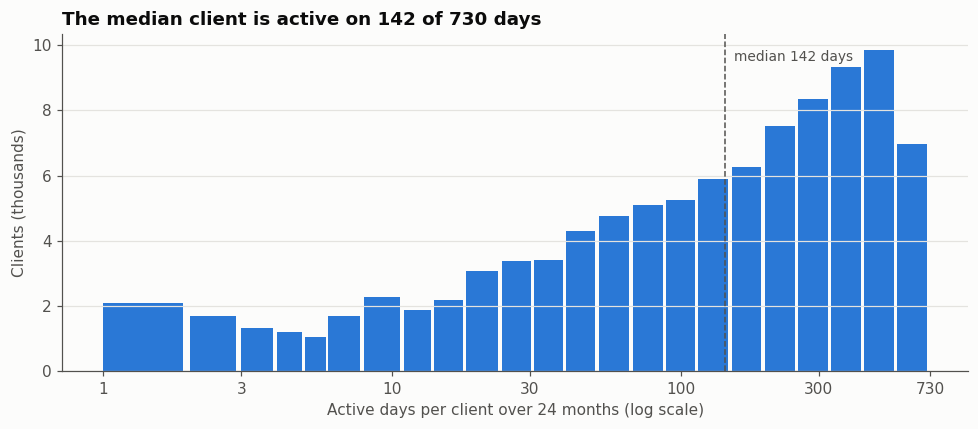

In [78]:
x = per_client["active_days"].to_numpy()
# Log-spaced bins on whole days, so small counts (1, 2, 3 days) do not leave empty bins
edges = np.unique(np.round(np.logspace(0, np.log10(x.max() + 1), 26)))
counts, edges = np.histogram(x, bins=edges)

fig, ax = plt.subplots()
ax.bar(edges[:-1], counts / 1e3, width=np.diff(edges) * 0.88, align="edge", color=BLUE)
ax.set_xscale("log")
ticks = [1, 3, 10, 30, 100, 300, 730]
ax.set_xticks(ticks, [str(t) for t in ticks])
ax.xaxis.set_minor_locator(mticker.NullLocator())
ax.set_xlabel("Active days per client over 24 months (log scale)")
ax.set_ylabel("Clients (thousands)")
median = per_client["active_days"].median()
ax.axvline(median, color=INK_2, lw=1, ls="--")
ax.annotate(f"median {median:.0f} days", (median, ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color=INK_2, fontsize=9)
ax.set_title(f"The median client is active on {median:.0f} of 730 days")
plt.tight_layout()
plt.show()

In [79]:
joined = (per_client.group_by(pl.col("first_day").dt.truncate("1mo").alias("month"))
          .len().sort("month").to_pandas().set_index("month"))
print(f"clients whose first transaction is in Jan 2021: {joined['len'].iloc[0]:,} "
      f"({joined['len'].iloc[0] / per_client.height:.0%})")
print(f"clients who first appear later (new or returning clients): {per_client.height - joined['len'].iloc[0]:,}")
joined.T

clients whose first transaction is in Jan 2021: 69,205 (70%)
clients who first appear later (new or returning clients): 29,516


month,2021-01-01,2021-02-01,2021-03-01,2021-04-01,2021-05-01,2021-06-01,2021-07-01,2021-08-01,2021-09-01,2021-10-01,...,2022-03-01,2022-04-01,2022-05-01,2022-06-01,2022-07-01,2022-08-01,2022-09-01,2022-10-01,2022-11-01,2022-12-01
len,69205,3877,2457,1725,1417,1242,1189,1048,1013,1001,...,1100,1038,1052,1127,1164,1073,1068,1104,1130,927


**Result.** Activity is very uneven. The median client transacts on 142 of 730 days;
one in ten is active on 9 days or fewer. One client has over a million transactions,
probably a payment processor; it is kept, since the label depends on active days, not
on volume.

Seventy percent of clients already transact in January 2021. The early months also catch
existing clients whose first transaction simply came later; from mid-2021 about 1,000
to 1,200 clients appear for the first time each month. So the population **grows** over
time, and new clients have a short history when they are scored. Features must cope with
that, for example with a tenure feature.

### Activity over time

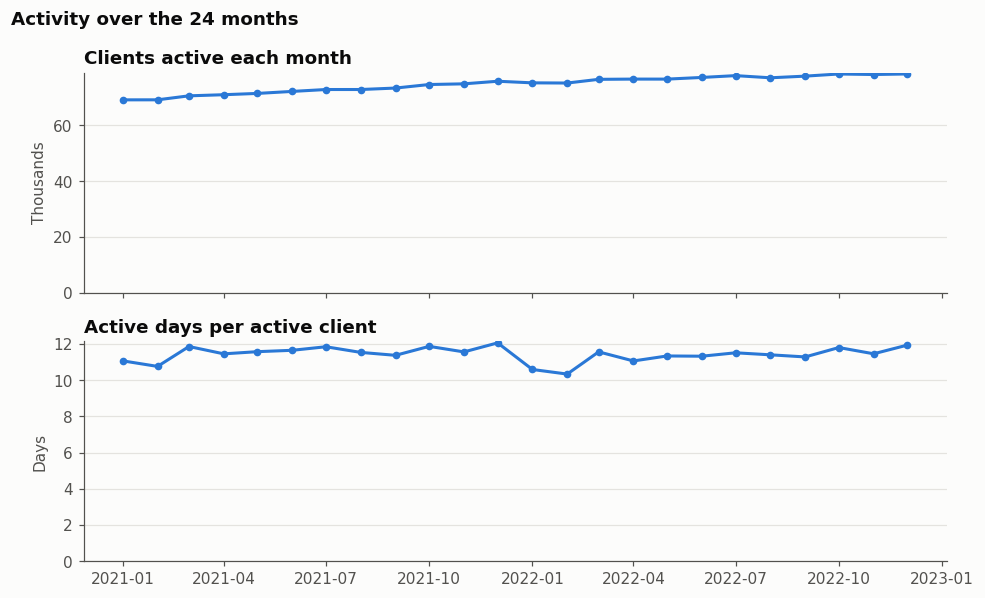

In [80]:
monthly = (
    active_days.group_by(pl.col("day").dt.truncate("1mo").alias("month"))
    .agg(pl.col("client_key").n_unique().alias("active_clients"), pl.len().alias("client_days"))
    .sort("month").to_pandas().set_index("month")
)
monthly["active_days_per_client"] = monthly["client_days"] / monthly["active_clients"]

fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
axes[0].plot(monthly.index, monthly["active_clients"] / 1e3, color=BLUE, lw=2, marker="o", ms=4)
axes[0].set_ylabel("Thousands")
axes[0].set_title("Clients active each month")
axes[0].set_ylim(0, None)
axes[1].plot(monthly.index, monthly["active_days_per_client"], color=BLUE, lw=2, marker="o", ms=4)
axes[1].set_ylabel("Days")
axes[1].set_title("Active days per active client")
axes[1].set_ylim(0, None)
fig.suptitle("Activity over the 24 months", x=0.01, ha="left", fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

**Result.** There are no missing months or sudden breaks. Active clients grow steadily
from about 69,000 to 78,000 a month, and an active client transacts on 11 to 12 days a
month. The small dips in January and February each year fit the long New Year holidays
and February's shorter month. The data feed looks stable enough to compare months.

### When does inactivity become dormancy?

An **inactivity spell** is the run of days between two active days, or between the last
active day and the end of the data. Banks call an account dormant once a spell reaches
some length N. The data does not tell us N, so we choose it from the data.

The question that decides N: *once a client has been inactive for d days, how likely are
they to come back soon?* If most clients come back after 20 quiet days, 20 days is a
pause, not dormancy. N should sit where coming back becomes the exception.

For each threshold d we take every spell that reached d days, keep only those with at
least 90 days of data after day d (so a return could be seen), and measure the share
that ended with a transaction within those 90 days.

In [81]:
END = LAST_DAY + timedelta(days=1)   # first day after the data

spells = (
    active_days
    .with_columns(pl.col("day").shift(-1).over("client_key").alias("next_day"))
    .with_columns(
        pl.col("next_day").is_null().alias("censored"),                     # last spell: still running at END
        pl.coalesce("next_day", pl.lit(END)).alias("spell_end"),
    )
    .with_columns(((pl.col("spell_end") - pl.col("day")).dt.total_days() - 1).alias("inactive_days"))
    .rename({"day": "start"})
    .select("client_key", "start", "next_day", "inactive_days", "censored")
    .filter(pl.col("inactive_days") > 0)
)
print(f"inactivity spells (at least one quiet day): {spells.height:,}")
print(f"  of which still running at the end of the data: {spells['censored'].sum():,}")
spells.select("inactive_days").to_pandas().describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).T

inactivity spells (at least one quiet day): 8,643,657
  of which still running at the end of the data: 70,271


,count,mean,std,min,50%,75%,90%,95%,99%,max
inactive_days,8643657.0,4.833553,15.504144,1.0,2.0,4.0,9.0,15.0,46.0,728.0


In [82]:
FOLLOW_UP = 90
rows = []
for d in range(7, 181, 1):
    reached = spells.filter(pl.col("inactive_days") >= d).with_columns(
        (pl.col("start") + pl.duration(days=d)).alias("day_d"))
    eligible = reached.filter(pl.col("day_d") + pl.duration(days=FOLLOW_UP) <= pl.lit(LAST_DAY))
    returned = eligible.filter(~pl.col("censored") &
                               (pl.col("next_day") <= pl.col("day_d") + pl.duration(days=FOLLOW_UP)))
    rows.append({"d": d, "spells_reaching_d": eligible.height,
                 "return_within_90d": returned.height / max(eligible.height, 1)})
reactivation = pd.DataFrame(rows).set_index("d")
reactivation.loc[[7, 14, 30, 45, 60, 90, 120, 180]]

,spells_reaching_d,return_within_90d
d,,
7,1098410,0.969135
14,438509,0.928736
30,142184,0.814803
45,76533,0.702220
60,50174,0.602424
90,29869,0.495865
120,20622,0.431384
180,11120,0.365288


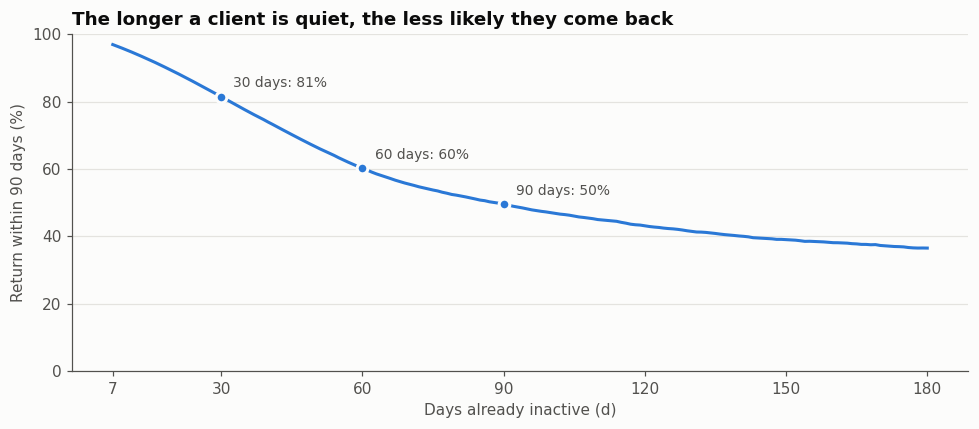

In [83]:
fig, ax = plt.subplots()
ax.plot(reactivation.index, reactivation["return_within_90d"] * 100, color=BLUE, lw=2)
for n in (30, 60, 90):
    y = reactivation.loc[n, "return_within_90d"] * 100
    ax.plot(n, y, "o", color=BLUE, ms=7, mec="#fcfcfb", mew=2)
    ax.annotate(f"{n} days: {y:.0f}%", (n, y), xytext=(8, 6), textcoords="offset points",
                color=INK_2, fontsize=9)
ax.set_xlabel("Days already inactive (d)")
ax.set_ylabel("Return within 90 days (%)")
ax.set_ylim(0, 100)
ax.set_xticks([7, 30, 60, 90, 120, 150, 180])
ax.set_title("The longer a client is quiet, the less likely they come back")
plt.tight_layout()
plt.show()

**Result.** Most quiet spells are short: the median is 2 days and 99% end within 46 days.
The return curve falls smoothly, **with no sharp elbow**: 81% of clients come back within
90 days after 30 quiet days, 60% after 60 days, 50% after 90 days and still 37% after 180
days. Corporate clients pause and come back far more than the word "dormant" suggests.

So the data cannot pick N on its own; it is partly a business choice. What the curve
does show is how much each N means: at 30 days, four in five "dormant" clients come back
soon, so the label would mostly mark ordinary pauses.

### Dormancy windows compared

A good N balances three things: coming back after N days should be rare (the label means
something), dormancy should be common enough to learn from, and the bank should still
have time to act. The table compares candidates using monthly **scoring dates**: on
each date, the **at-risk** clients are those that have transacted before and are not
already dormant; the **event** is crossing N quiet days within the next 90 days.

In [84]:
HORIZON = 90
SCORING_DATES = [date(y, m, 1) for y in (2021, 2022) for m in range(1, 13)
                 if date(2021, 4, 1) <= date(y, m, 1) <= date(2022, 10, 1)]
print(f"{len(SCORING_DATES)} scoring dates: {SCORING_DATES[0]} to {SCORING_DATES[-1]}")
print("(starting April 2021 leaves 90 days of history for features;"
      " ending October 2022 leaves 90 days to observe the outcome)")


def crossings(n: int) -> pl.DataFrame:
    # Day on which each spell reaches n quiet days, if it does inside the data
    return (spells.filter(pl.col("inactive_days") >= n)
            .with_columns((pl.col("start") + pl.duration(days=n)).alias("cross_day"))
            .filter(pl.col("cross_day") <= pl.lit(LAST_DAY))
            .select("client_key", "cross_day").sort("client_key", "cross_day"))


def scoring_panel(n: int, horizon: int = HORIZON) -> pl.DataFrame:
    cross = crossings(n)
    frames = []
    for t in SCORING_DATES:
        last_before = (active_days.filter(pl.col("day") < t)
                       .group_by("client_key").agg(pl.col("day").max().alias("last_active")))
        at_risk = (last_before
                   .with_columns(((pl.lit(t) - pl.col("last_active")).dt.total_days()).alias("days_since_last"))
                   .filter(pl.col("days_since_last") <= n)       # fewer than n quiet days: not yet dormant
                   .with_columns(pl.lit(t).alias("score_date")))
        nxt = (at_risk.sort("client_key")
               .join_asof(cross.rename({"cross_day": "next_cross"}), left_on="score_date",
                          right_on="next_cross", by="client_key", strategy="forward",
                          check_sortedness=False))
        frames.append(nxt.with_columns(
            (pl.col("next_cross").is_not_null() &
             (pl.col("next_cross") <= pl.col("score_date") + pl.duration(days=horizon))).alias("event")))
    return pl.concat(frames)


summary = []
panels = {}
for n in (30, 45, 60, 90, 180):
    panel = scoring_panel(n)
    panels[n] = panel
    ever = crossings(n)["client_key"].n_unique() / population.height
    summary.append({
        "N (quiet days)": n,
        "return within 90d after N": reactivation.loc[n, "return_within_90d"],
        "clients ever dormant": ever,
        "at-risk rows (all dates)": panel.height,
        "event rate per scoring date": panel["event"].mean(),
    })
pd.DataFrame(summary).set_index("N (quiet days)").style.format({
    "return within 90d after N": "{:.0%}", "clients ever dormant": "{:.0%}",
    "at-risk rows (all dates)": "{:,}", "event rate per scoring date": "{:.1%}"})

19 scoring dates: 2021-04-01 to 2022-10-01
(starting April 2021 leaves 90 days of history for features; ending October 2022 leaves 90 days to observe the outcome)


,return within 90d after N,clients ever dormant,at-risk rows (all dates),event rate per scoring date
N (quiet days),,,,
30,81%,49%,"1,418,511",18.8%
45,70%,39%,"1,469,511",12.5%
60,60%,32%,"1,499,829",9.2%
90,50%,25%,"1,539,167",6.5%
180,37%,13%,"1,595,993",2.6%


**Decision: N = 90 quiet days**, with N = 60 kept as a sensitivity check.

- **It matches practice.** The dissertation concept note says banks flag dormancy after
  90 to 180 days of no activity. N = 90 is the earliest of those flags, so the model
  warns before the bank's first formal flag.
- **The label means something.** After 90 quiet days, half of clients do not come back
  within the next 90 days. At 30 to 60 days most do, so the label would mark pauses.
- **There are still enough events.** About 6.5% of at-risk clients cross the threshold
  within 90 days, roughly 100,000 positive rows across all scoring dates. At N = 180 the
  rate falls to 2.6%, and with 24 months of data far fewer 180-day spells are observable.

*Honest limitation:* even at N = 90, half of the clients who cross the threshold
transact again later. The label therefore means **"crosses the bank's inactivity
threshold"**, the point that triggers dormancy handling, not "lost for good".

### At-risk population and event rate per scoring date (N = 90)

Check that the label is stable across time.

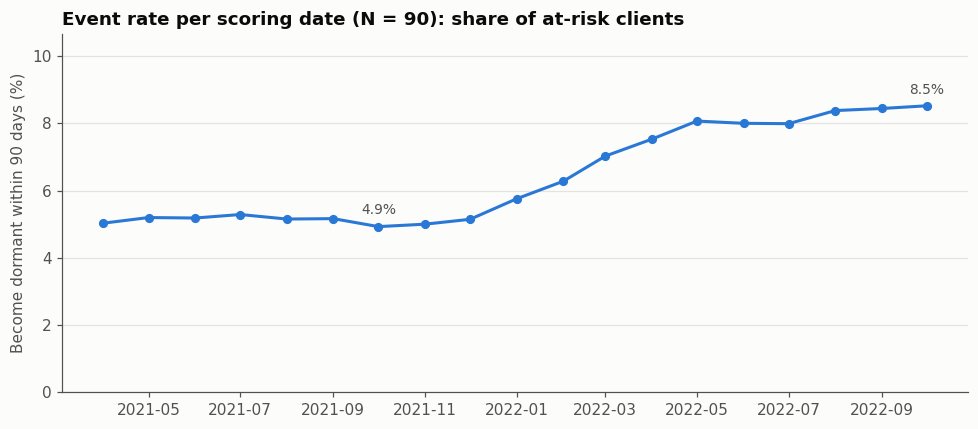

score_date,2021-04-01 00:00:00,2021-05-01 00:00:00,2021-06-01 00:00:00,2021-07-01 00:00:00,2021-08-01 00:00:00,2021-09-01 00:00:00,2021-10-01 00:00:00,2021-11-01 00:00:00,2021-12-01 00:00:00,2022-01-01 00:00:00,2022-02-01 00:00:00,2022-03-01 00:00:00,2022-04-01 00:00:00,2022-05-01 00:00:00,2022-06-01 00:00:00,2022-07-01 00:00:00,2022-08-01 00:00:00,2022-09-01 00:00:00,2022-10-01 00:00:00
at_risk,"75,539.000","76,211.000","76,824.000","77,417.000","77,878.000","78,475.000","78,964.000","79,678.000","80,392.000","81,159.000","81,774.000","82,585.000","83,298.000","83,883.000","84,254.000","84,699.000","84,978.000","85,347.000","85,812.000"
event_rate,0.050,0.052,0.052,0.053,0.052,0.052,0.049,0.050,0.051,0.058,0.063,0.070,0.075,0.081,0.080,0.080,0.084,0.084,0.085


In [85]:
N = 90   # chosen in section 5; change here to rerun sections 6-8 for another window
panel = panels[N]
by_date = (panel.group_by("score_date").agg(pl.len().alias("at_risk"), pl.col("event").mean().alias("event_rate"))
           .sort("score_date").to_pandas().set_index("score_date"))

fig, ax = plt.subplots()
ax.plot(by_date.index, by_date["event_rate"] * 100, color=BLUE, lw=2, marker="o", ms=5)
ax.set_ylim(0, by_date["event_rate"].max() * 100 * 1.25)
ax.set_ylabel("Become dormant within 90 days (%)")
ax.set_title(f"Event rate per scoring date (N = {N}): share of at-risk clients")
lo, hi = by_date["event_rate"].idxmin(), by_date["event_rate"].idxmax()
for when in (lo, hi):
    ax.annotate(f"{by_date.loc[when, 'event_rate']:.1%}", (when, by_date.loc[when, "event_rate"] * 100),
                xytext=(0, 8), textcoords="offset points", ha="center", color=INK_2, fontsize=9)
plt.tight_layout()
plt.show()
by_date.T.style.format("{:,.3f}")

**Result.** Two things change over time:

- **The at-risk population grows** from about 75,500 to 85,800 clients, matching the
  steady arrival of new clients.
- **The event rate drifts upwards.** It stays near 5% until late 2021, then climbs
  through 2022 to about 8.5%. The data does not say why.

Consequences for modelling: the out-of-time test period (the latest dates) has a
higher base rate than the training period. A model trained on 2021 alone would
under-predict risk in 2022, so calibration has to be checked on the test period, recent
dates should be in training, and this is exactly the kind of shift the drift monitoring
in the proposal is meant to catch.

### How much does recency alone tell us?

The simplest early-warning rule is "flag clients who have been quiet for a while". If
recency already separates the classes almost perfectly, a model adds little; if not,
there is room for the other signals. This also previews the **rule baseline** the models
must beat.

rows already quiet 30+ days: 7.8% of rows, 65.3% of events


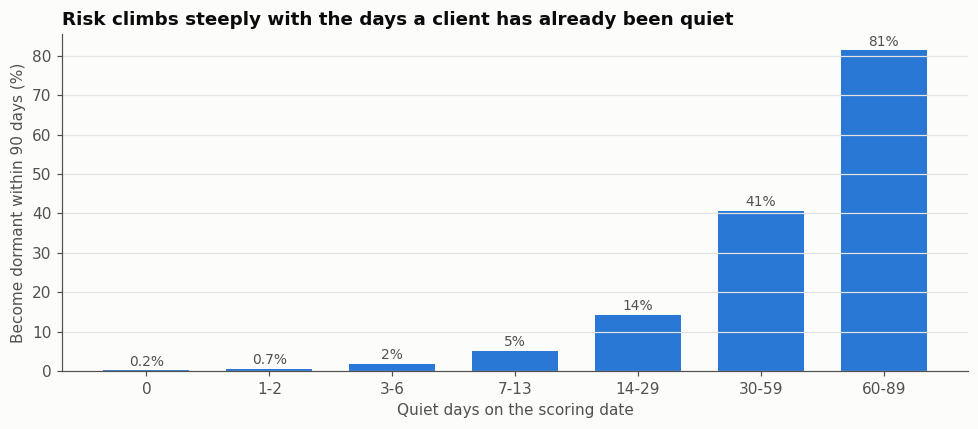

,rows,event_rate,share_of_rows,events
bucket,,,,
0,"534,817",0.2%,34.7%,"1,227"
1-2,"358,153",0.7%,23.3%,"2,353"
3-6,"241,599",1.9%,15.7%,"4,693"
7-13,"157,632",5.2%,10.2%,"8,203"
14-29,"126,310",14.3%,8.2%,"18,125"
30-59,"81,318",40.6%,5.3%,"33,052"
60-89,"39,338",81.4%,2.6%,"32,020"


In [86]:
edges_q = [0, 1, 3, 7, 14, 30, 60, N]
labels = ["0", "1-2", "3-6", "7-13", "14-29", "30-59", f"60-{N - 1}"]
quiet = panel.select((pl.col("days_since_last") - 1).alias("quiet_days"), "event").to_pandas()
quiet["bucket"] = pd.cut(quiet["quiet_days"], bins=edges_q, labels=labels, right=False)
recency = quiet.groupby("bucket", observed=False).agg(rows=("event", "size"), event_rate=("event", "mean"))
recency["share_of_rows"] = recency["rows"] / recency["rows"].sum()
recency["events"] = recency["rows"] * recency["event_rate"]
late = ["30-59", f"60-{N - 1}"]
print(f"rows already quiet 30+ days: {recency.loc[late, 'rows'].sum() / recency['rows'].sum():.1%} of rows, "
      f"{recency.loc[late, 'events'].sum() / recency['events'].sum():.1%} of events")

fig, ax = plt.subplots()
ax.bar(range(len(recency)), recency["event_rate"] * 100, color=BLUE, width=0.7)
ax.set_xticks(range(len(recency)), recency.index)
ax.set_xlabel("Quiet days on the scoring date")
ax.set_ylabel("Become dormant within 90 days (%)")
for i, v in enumerate(recency["event_rate"] * 100):
    ax.annotate(f"{v:.1f}%" if v < 1 else f"{v:.0f}%", (i, v), xytext=(0, 3), textcoords="offset points", ha="center", color=INK_2, fontsize=9)
ax.set_title("Risk climbs steeply with the days a client has already been quiet")
plt.tight_layout()
plt.show()
recency.style.format({"rows": "{:,}", "event_rate": "{:.1%}", "share_of_rows": "{:.1%}", "events": "{:,.0f}"})

**Result.** Recency is a strong signal, but it splits the problem into two very
different parts:

- **Clients already quiet for 30+ days** are 8% of at-risk rows but produce about two
  thirds of the events (see the printed share above). For them, the outcome is close to
  decided; a simple "days quiet" rule catches them.
- **Clients active in the last week** are about three quarters of the rows, with event
  rates of 0.2 to 2%. Here recency says little, and this is where an early warning is
  worth the most, because the bank can still act.

So: the **rule baseline** will be "days quiet", and model results will be reported
**separately for clients quiet fewer than 30 days**. A model that only rediscovers
recency would look good overall and add nothing where it matters.

### Is there a warning signal before dormancy?

Compare two groups over the 26 weeks leading up to an anchor day:

- **Became dormant:** each client's first spell of N+ quiet days; the anchor is the
  last active day before it.
- **Stayed active:** clients who never had an N-day spell; the anchor is a random active
  day, so both groups are anchored on a day with activity.

Activity is measured as active days per week and indexed to each group's own level 14 to
26 weeks before the anchor (= 100). A falling line means activity was already fading.

In [87]:
WEEKS = 26
early = FIRST_DAY + timedelta(days=7 * WEEKS)          # need 26 weeks of history
late = LAST_DAY - timedelta(days=N)                    # dormant anchors need N days of follow-up

dormant_anchor = (crossings(N).group_by("client_key").agg(pl.col("cross_day").min())
                  .with_columns((pl.col("cross_day") - pl.duration(days=N)).alias("anchor"))
                  .filter(pl.col("anchor").is_between(early, late))
                  .select("client_key", "anchor").with_columns(pl.lit("Became dormant").alias("group")))

ever_dormant = crossings(N)["client_key"].unique()
active_anchor = (active_days.filter(~pl.col("client_key").is_in(ever_dormant.implode())
                                    & pl.col("day").is_between(early, late))
                 .group_by("client_key").agg(pl.col("day").shuffle(seed=42).first().alias("anchor"))
                 .with_columns(pl.lit("Stayed active").alias("group")))
anchors = pl.concat([dormant_anchor, active_anchor.select(dormant_anchor.columns)])
print(anchors.group_by("group").len())

weekly = (anchors.join(active_days, on="client_key")
          .with_columns(((pl.col("anchor") - pl.col("day")).dt.total_days() // 7 + 1).alias("weeks_before"))
          .filter(pl.col("weeks_before").is_between(1, WEEKS) & (pl.col("day") <= pl.col("anchor")))
          .group_by("group", "weeks_before").agg(pl.len().alias("days"))
          .join(anchors.group_by("group").len().rename({"len": "clients"}), on="group")
          .with_columns((pl.col("days") / pl.col("clients")).alias("active_days_per_week"))
          .sort("group", "weeks_before").to_pandas())
pivot = weekly.pivot(index="weeks_before", columns="group", values="active_days_per_week").sort_index()
index = pivot / pivot.loc[14:26].mean() * 100
# Week 1 always contains the anchor, an active day by construction, so it is left out of the chart
plot_index = index.loc[2:]
pivot.round(2).T

shape: (2, 2)
┌────────────────┬───────┐
│ group          ┆ len   │
│ ---            ┆ ---   │
│ str            ┆ u32   │
╞════════════════╪═══════╡
│ Became dormant ┆ 16966 │
│ Stayed active  ┆ 71125 │
└────────────────┴───────┘


weeks_before,1,2,3,4,5,6,7,8,9,10,...,17,18,19,20,21,22,23,24,25,26
group,,,,,,,,,,,,,,,,,,,,,
Became dormant,1.34,0.45,0.50,0.54,0.57,0.56,0.53,0.53,0.53,0.55,...,0.59,0.59,0.61,0.60,0.62,0.62,0.63,0.62,0.64,0.63
Stayed active,3.49,2.88,2.86,2.85,2.82,2.79,2.77,2.76,2.77,2.76,...,2.71,2.71,2.70,2.69,2.68,2.68,2.67,2.66,2.66,2.65


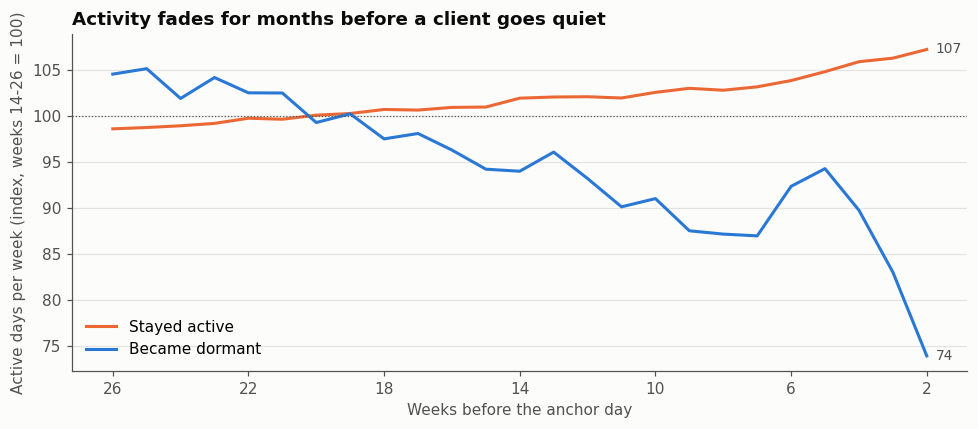

In [88]:
fig, ax = plt.subplots()
for group, color in [("Stayed active", ORANGE), ("Became dormant", BLUE)]:
    ax.plot(-plot_index.index, plot_index[group], color=color, lw=2, label=group)
    ax.annotate(f"{plot_index.loc[2, group]:.0f}", (-2, plot_index.loc[2, group]),
                xytext=(6, 0), textcoords="offset points", va="center", color=INK_2, fontsize=9)
ax.axhline(100, color=INK_2, lw=0.8, ls=":")
ax.set_xlabel("Weeks before the anchor day")
ax.set_xticks([-26, -22, -18, -14, -10, -6, -2])
ax.set_ylabel("Active days per week (index, weeks 14-26 = 100)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{-int(v)}"))
ax.legend(loc="lower left")
ax.set_title("Activity fades for months before a client goes quiet")
plt.tight_layout()
plt.show()

**Result.** There is a clear warning signal. Clients who go dormant are already much
less active (about 0.6 active days a week against 2.7), and **their activity fades for
about four months before the last transaction**: roughly 10% down by week 10 and 26% down
in the final two weeks. Clients who stay active hold steady or rise slightly.

*Caveat:* the rising line for "stayed active" is partly built in, because those anchors
are active days of clients who stayed active. The useful part is the shape of the
dormant line. It argues for **trend features** (recent weeks against earlier weeks), not
only levels.

### What kinds of transactions are there?

In [89]:
types = run(trx.group_by("event_type").agg(pl.len().alias("rows"), pl.col("client_key").n_unique().alias("clients")))
types = types.with_columns((pl.col("rows") / pl.col("rows").sum()).alias("share_of_rows"),
                           (pl.col("clients") / population.height).alias("share_of_clients")).sort("rows", descending=True)
top = types.head(10).to_pandas().set_index("event_type")
print(f"{types.height} transaction types; the top 10 cover {top['share_of_rows'].sum():.0%} of rows")
top.style.format({"rows": "{:,}", "clients": "{:,}", "share_of_rows": "{:.1%}", "share_of_clients": "{:.0%}"})

55 transaction types; the top 10 cover 91% of rows


,rows,clients,share_of_rows,share_of_clients
event_type,,,,
1,"16,763,280","91,395",43.2%,93%
46,"5,594,429","56,139",14.4%,57%
40,"4,524,387","44,803",11.7%,45%
49,"2,991,195","40,759",7.7%,41%
11,"2,091,135","34,629",5.4%,35%
56,"819,612","38,157",2.1%,39%
41,"797,243","35,046",2.1%,36%
50,"686,953","26,763",1.8%,27%
18,"602,747","28,976",1.6%,29%


**Result.** Transaction types are highly concentrated. Type 1 alone is 43% of rows and is
used by 93% of clients; the top 10 types cover 91% of rows. Type 48, the one with the
most missing attributes, is used by only 8% of clients.

**Decision.** Features will count activity for the top types separately and group the
rest as "other". A change in a client's transaction mix may itself be a signal.

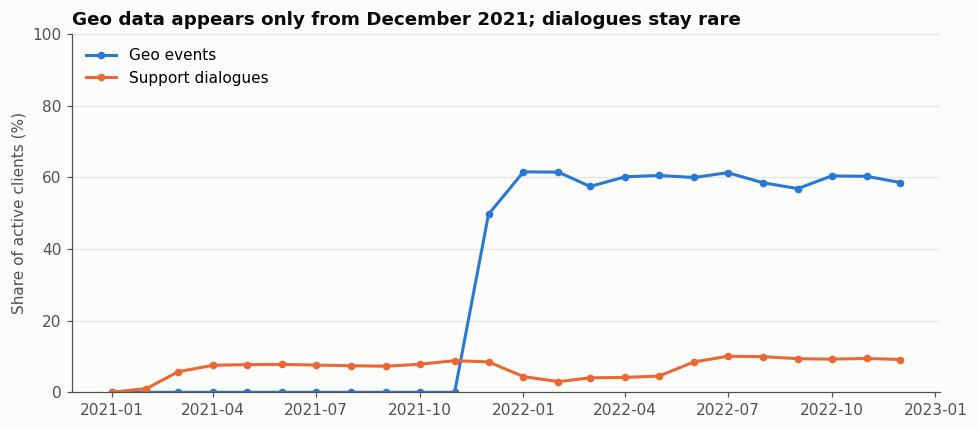

In [90]:
month_active = active_days.select("client_key", pl.col("day").dt.truncate("1mo").alias("month")).unique()
geo_months = run(pl.scan_parquet(INTERIM / "geo_clean.parquet")
                 .select("client_key", pl.col("event_time_local").dt.date().dt.truncate("1mo").alias("month")).unique())
dialog_months = (pl.read_parquet(INTERIM / "dialog_clean.parquet", columns=["client_key", "event_time_local"])
                 .select("client_key", pl.col("event_time_local").dt.date().dt.truncate("1mo").alias("month")).unique())
coverage = (month_active
            .join(geo_months.with_columns(pl.lit(True).alias("geo")), on=["client_key", "month"], how="left")
            .join(dialog_months.with_columns(pl.lit(True).alias("dialog")), on=["client_key", "month"], how="left")
            .group_by("month").agg(pl.col("geo").is_not_null().mean(), pl.col("dialog").is_not_null().mean())
            .sort("month").to_pandas().set_index("month"))

fig, ax = plt.subplots()
ax.plot(coverage.index, coverage["geo"] * 100, color=BLUE, lw=2, marker="o", ms=4, label="Geo events")
ax.plot(coverage.index, coverage["dialog"] * 100, color=ORANGE, lw=2, marker="o", ms=4, label="Support dialogues")
ax.set_ylim(0, 100)
ax.set_ylabel("Share of active clients (%)")
ax.legend(loc="upper left")
ax.set_title("Geo data appears only from December 2021; dialogues stay rare")
plt.tight_layout()
plt.show()

**Result.** Geo data is absent until December 2021 and then covers about 60% of active
clients each month from January 2022. Support dialogues reach 5 to 10% of active clients
a month.

**Decision.** The core model uses **transaction features only**, so all 19 scoring dates
can be used. Geo and dialogue features are tested as an **add-on** on 2022 scoring dates
(from March 2022, once 90 days of geo history exist), to see whether they add anything
beyond transactions. Dialogues start as simple counts and recency; the 768-dimension
embeddings are a stretch goal.

### Summary and decisions

| Question | Decision
|---|---|
| Dormancy window N | **90 quiet days** (60 as sensitivity) |
| Label | Crosses N quiet days within 30, 60 and 90 days of the scoring date |
| Scoring dates | 19 monthly dates, 1 Apr 2021 to 1 Oct 2022 |
| At-risk population | Transacted before the date and fewer than N days quiet |
| Censoring | None needed for the 90-day horizon on these dates |
| Baseline | Days quiet on the scoring date |
| Evaluation | Out-of-time split; results also for clients quiet < 30 days |
| Drift | Event rate rises from about 5% to 8.5% |
| Core features | Activity level, trend (recent vs earlier weeks), recency, tenure, transaction-type mix, amounts in currency 11 |
| Geo and dialogue | Add-on test on 2022 dates only |

### Labels, features and the train/test split

- **features** computed only from data *before* the scoring date,
- **labels**: does the client cross 90 quiet days within 30, 60 or 90 days, and when,
- a **split** column: train, validation or test, separated in time with gaps.

In [91]:
N = 90                                   # quiet days that define dormancy
HORIZONS = (30, 60, 90)
H = max(HORIZONS)
LOOKBACK = 90                            # feature window
LAST_DAY = date(2022, 12, 31)            # last observed day (local time)
SCORING_DATES = [date(y, m, 1) for y in (2021, 2022) for m in range(1, 13)
                 if date(2021, 4, 1) <= date(y, m, 1) <= date(2022, 10, 1)]
GEO_FROM = date(2022, 3, 1)              # first date with a full 90 days of geo history


def run(lf: pl.LazyFrame) -> pl.DataFrame:
    return lf.collect(engine="streaming")


trx = pl.scan_parquet(INTERIM / "trx_clean.parquet")
print(f"{len(SCORING_DATES)} scoring dates, {SCORING_DATES[0]} to {SCORING_DATES[-1]}")

19 scoring dates, 2021-04-01 to 2022-10-01


In [117]:
PROCESSED = ROOT
PROCESSED.mkdir(parents=True, exist_ok=True)

### Split, before any features

Each label looks **90 days ahead**. If a training date's outcome window overlaps the test
period, the model is trained on outcomes that happen during the test period, which is
leakage. So the three sets are separated by gaps of at least 90 days:

| Set | Scoring dates | Purpose |
|---|---|---|
| Train | Apr 2021 to Nov 2021 (8) | Fit models |
| *gap* | Dec 2021, Jan 2022 | Outcome windows of train dates run into these months |
| Validation | Feb 2022 to Apr 2022 (3) | Tune hyperparameters, choose models |
| *gap* | May 2022, Jun 2022 | |
| Test | Jul 2022 to Oct 2022 (4) | Final, untouched evaluation |

After tuning, the chosen model is **refit on every date up to April 2022** (train, first gap
and validation; their outcome windows all end before the test period starts) and scored
once on the test dates.

The split also has to be fixed before looking at features, so that choices like "which
transaction types count as top 10" use **training dates only**.

In [92]:
def split_of(t: date) -> str:
    if t <= date(2021, 11, 1):
        return "train"
    if date(2022, 2, 1) <= t <= date(2022, 4, 1):
        return "validation"
    if t >= date(2022, 7, 1):
        return "test"
    return "gap"


split_table = pd.DataFrame({"score_date": SCORING_DATES, "split": [split_of(t) for t in SCORING_DATES]})
split_table["outcome_window_ends"] = split_table["score_date"] + pd.Timedelta(days=H)
REFIT_END = date(2022, 4, 1)          # final model is refit on every date up to here
split_table["in_refit"] = split_table["score_date"] <= REFIT_END

# Checks: train windows end before validation starts; every window in the refit set
# ends before the test period starts. (The May and June 2022 gap dates are never used.)
first_val = split_table.loc[split_table.split == "validation", "score_date"].min()
first_test = split_table.loc[split_table.split == "test", "score_date"].min()
assert split_table.loc[split_table.split == "train", "outcome_window_ends"].max() < first_val
assert split_table.loc[split_table.in_refit, "outcome_window_ends"].max() < first_test
print("Split checks passed.")
split_table.groupby("split", sort=False)["score_date"].agg(["count", "min", "max"])

Split checks passed.


,count,min,max
split,,,
train,8,2021-04-01,2021-11-01
gap,4,2021-12-01,2022-06-01
validation,3,2022-02-01,2022-04-01
test,4,2022-07-01,2022-10-01


In [96]:
BLUE, ORANGE, AQUA, GAP_GREY = "#2a78d6", "#eb6834", "#1baf7a", "#b5b3ad"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": INK_2, "axes.labelcolor": INK_2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "legend.frameon": False,
})

In [98]:
import matplotlib.dates as mdates

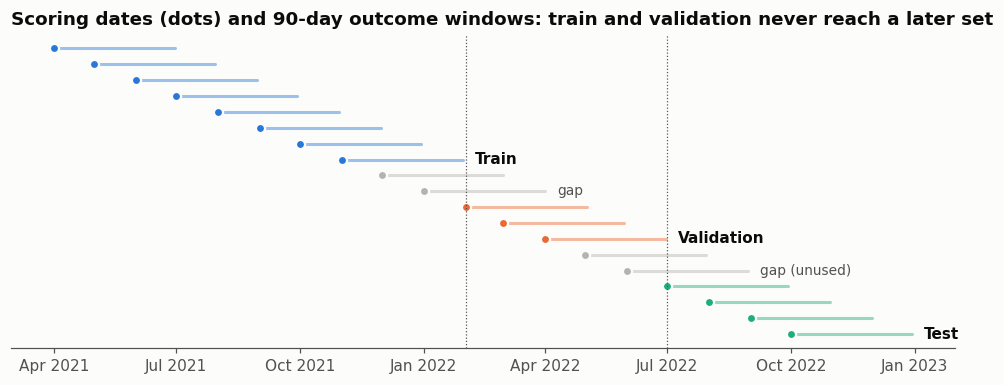

In [99]:
colors = {"train": BLUE, "validation": ORANGE, "test": AQUA, "gap": GAP_GREY}
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, row in split_table.iterrows():
    y = -i
    c = colors[row.split]
    ax.plot([row.score_date, row.outcome_window_ends], [y, y], color=c, lw=2, alpha=0.45, solid_capstyle="round")
    ax.plot(row.score_date, y, "o", color=c, ms=6, mec="#fcfcfb", mew=1.5)
for split in ("train", "validation", "test"):
    last_i = split_table.index[split_table.split == split][-1]
    ax.annotate(split.capitalize(), (split_table.loc[last_i, "outcome_window_ends"], -last_i), xytext=(8, 0),
                textcoords="offset points", color=INK, fontsize=10, fontweight="bold", va="center")
for gap_i in split_table.index[split_table.split == "gap"][1::2]:
    ax.annotate("gap (unused)" if split_table.loc[gap_i, "score_date"] > REFIT_END else "gap",
                (split_table.loc[gap_i, "outcome_window_ends"], -gap_i), xytext=(8, 0),
                textcoords="offset points", color=INK_2, fontsize=9, va="center")
ax.axvline(first_val, color=INK_2, lw=0.8, ls=":")
ax.axvline(first_test, color=INK_2, lw=0.8, ls=":")
ax.set_yticks([])
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_title("Scoring dates (dots) and 90-day outcome windows: train and validation never reach a later set")
plt.tight_layout()
plt.show()

### Daily activity table

Features are counts and sums over windows of days, so transactions are first rolled up
to **one row per client per active day**. Transaction types are bucketed into the 10 most
common types (counted on training dates only) plus "other". Amounts are summed in the
domestic currency

In [100]:
TRAIN_END = date(2021, 11, 1)
top_types = (run(trx.filter(pl.col("event_time_local") < pl.lit(TRAIN_END))
                 .group_by("event_type").agg(pl.len().alias("rows")))
             .sort("rows", descending=True).head(10)["event_type"].to_list())
print("top 10 transaction types (training period):", top_types)

DOMESTIC = 11
daily = run(
    trx.with_columns(pl.col("event_time_local").dt.date().alias("day"))
    .group_by("client_key", "day")
    .agg(
        pl.len().cast(pl.Int32).alias("n_trx"),
        pl.col("amount").filter(pl.col("currency") == DOMESTIC).sum().alias("amount_dom"),
        *[(pl.col("event_type") == k).sum().cast(pl.Int32).alias(f"n_type_{k}") for k in top_types],
        (~pl.col("event_type").is_in(top_types)).sum().cast(pl.Int32).alias("n_type_other"),
    )
    .sort("client_key", "day")
)
daily.write_parquet(INTERIM / "daily_activity.parquet")
print(f"daily rows: {daily.height:,}; memory {daily.estimated_size() / 1e9:.2f} GB")
daily.head()

top 10 transaction types (training period): [1, 46, 40, 49, 11, 56, 41, 50, 18, 48]
daily rows: 20,496,511; memory 1.23 GB


client_key,day,n_trx,amount_dom,n_type_1,n_type_46,n_type_40,n_type_49,n_type_11,n_type_56,n_type_41,n_type_50,n_type_18,n_type_48,n_type_other
i32,date,i32,f32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32
0,2021-09-16,1,6.668097,0,0,1,0,0,0,0,0,0,0,0
0,2021-11-12,1,737.651062,0,0,0,0,0,0,0,0,0,0,1
0,2021-12-16,1,1.356884,0,0,1,0,0,0,0,0,0,0,0
0,2022-01-15,1,181.289734,0,0,0,0,0,0,0,0,1,0,0
0,2022-02-11,1,7490.259766,0,0,1,0,0,0,0,0,0,0,0


In [101]:
END = LAST_DAY + timedelta(days=1)
spells = (
    daily.select("client_key", "day")
    .with_columns(pl.col("day").shift(-1).over("client_key").alias("next_day"))
    .with_columns(((pl.coalesce("next_day", pl.lit(END)) - pl.col("day")).dt.total_days() - 1).alias("inactive_days"))
    .rename({"day": "start"})
    .filter(pl.col("inactive_days") > 0)
)
# Day on which each spell reaches N quiet days (only if that day is inside the data)
crossings = (spells.filter(pl.col("inactive_days") >= N)
             .with_columns((pl.col("start") + pl.duration(days=N)).alias("cross_day"))
             .filter(pl.col("cross_day") <= pl.lit(LAST_DAY))
             .select("client_key", "cross_day").sort("client_key", "cross_day"))
print(f"spells: {spells.height:,}; spells reaching {N} quiet days inside the data: {crossings.height:,}")

spells: 8,643,657; spells reaching 90 quiet days inside the data: 37,089


In [102]:
END = LAST_DAY + timedelta(days=1)
spells = (
    daily.select("client_key", "day")
    .with_columns(pl.col("day").shift(-1).over("client_key").alias("next_day"))
    .with_columns(((pl.coalesce("next_day", pl.lit(END)) - pl.col("day")).dt.total_days() - 1).alias("inactive_days"))
    .rename({"day": "start"})
    .filter(pl.col("inactive_days") > 0)
)
# Day on which each spell reaches N quiet days (only if that day is inside the data)
crossings = (spells.filter(pl.col("inactive_days") >= N)
             .with_columns((pl.col("start") + pl.duration(days=N)).alias("cross_day"))
             .filter(pl.col("cross_day") <= pl.lit(LAST_DAY))
             .select("client_key", "cross_day").sort("client_key", "cross_day"))
print(f"spells: {spells.height:,}; spells reaching {N} quiet days inside the data: {crossings.height:,}")

spells: 8,643,657; spells reaching 90 quiet days inside the data: 37,089


### Labels

For a client at risk on date *t*, with last active day *a* before *t*, the current spell
reaches N quiet days on day *a + N*. At-risk means that day is still in the future
(*a + N > t*). The **event day** is the first crossing day after *t*, from the current
spell or a later one.

| Column | Meaning |
|---|---|
| `days_to_event` | days from *t* to the event day; empty if no event within 90 days |
| `event_30`, `event_60`, `event_90` | event within 30 / 60 / 90 days |
| `interval` | 1 = days 1-30, 2 = days 31-60, 3 = days 61-90, 0 = no event (for the discrete-time hazard model) |

Every outcome window ends inside the data (the last date is 1 Oct 2022, its window ends
30 Dec 2022), so **no row is censored** within the 90-day horizon.

In [103]:
def labels_for(at_risk: pl.DataFrame) -> pl.DataFrame:
    out = (at_risk.sort("client_key")
           .join_asof(crossings.rename({"cross_day": "next_cross"}), left_on="score_date",
                      right_on="next_cross", by="client_key", strategy="forward",
                      allow_exact_matches=False, check_sortedness=False)
           .with_columns((pl.col("next_cross") - pl.col("score_date")).dt.total_days().alias("dte")))
    out = out.with_columns(pl.when(pl.col("dte") <= H).then(pl.col("dte")).alias("days_to_event"))
    out = out.with_columns([(pl.col("days_to_event") <= h).fill_null(False).alias(f"event_{h}") for h in HORIZONS])
    out = out.with_columns(
        pl.when(pl.col("days_to_event").is_null()).then(0)
        .otherwise(((pl.col("days_to_event") - 1) // 30 + 1)).cast(pl.Int8).alias("interval"))
    return out.drop("next_cross", "dte")

### Features

All windows end the day **before** the scoring date: `day < t`. Five groups:

| Group | Features | Why |
|---|---|---|
| Recency and tenure | quiet days, tenure, lifetime activity rate, new-client flag | recency is the strongest single signal; new clients have short histories |
| Activity level | active days and transactions in the last 7, 30, 90 days; active weeks | dormant clients are far less active |
| Trend | last 30 days against the 60 days before, for days, transactions and amounts | activity fades for months before dormancy |
| Pausing history | longest recent gap, past gaps of 30+ and 90+ days | some clients pause and come back regularly |
| Transaction mix | share of each top-10 type in the last 90 days, number of type buckets used | a change of mix may signal disengagement |

In [104]:
def features_for(t: date) -> pl.DataFrame:
    t_lit = pl.lit(t)
    past = daily.filter(pl.col("day") < t_lit)

    lifetime = past.group_by("client_key").agg(
        pl.col("day").min().alias("first_day"),
        pl.col("day").max().alias("last_day"),
        pl.len().alias("active_days_total"),
    )
    at_risk = (lifetime
               .with_columns((t_lit - pl.col("last_day")).dt.total_days().alias("days_since_last"))
               .filter(pl.col("days_since_last") < N)                      # crossing day a + N is after t
               .with_columns(
                   t_lit.alias("score_date"),
                   (pl.col("days_since_last") - 1).alias("quiet_days"),
                   (t_lit - pl.col("first_day")).dt.total_days().alias("tenure_days"),
               ))

    w = past.filter(pl.col("day") >= t_lit - pl.duration(days=LOOKBACK))
    recent = lambda d: pl.col("day") >= t_lit - pl.duration(days=d)
    type_cols = [f"n_type_{k}" for k in top_types] + ["n_type_other"]
    window = w.group_by("client_key").agg(
        recent(7).sum().alias("active_days_7"),
        recent(30).sum().alias("active_days_30"),
        pl.len().alias("active_days_90"),
        pl.col("n_trx").filter(recent(30)).sum().alias("trx_30"),
        pl.col("n_trx").sum().alias("trx_90"),
        pl.col("amount_dom").filter(recent(30)).sum().alias("amount_30"),
        pl.col("amount_dom").sum().alias("amount_90"),
        ((t_lit - pl.col("day")).dt.total_days() // 7).n_unique().alias("active_weeks_90"),
        *[pl.col(c).sum().alias(c) for c in type_cols],
    )

    history = spells.filter(pl.col("next_day") < t_lit).group_by("client_key").agg(
        (pl.col("inactive_days") >= 30).sum().alias("past_gaps_30plus"),
        (pl.col("inactive_days") >= N).sum().alias("past_gaps_90plus"),
        pl.col("inactive_days").filter(pl.col("start") >= t_lit - pl.duration(days=LOOKBACK)).max().alias("max_gap_90"),
    )

    f = (at_risk.join(window, on="client_key", how="left")
         .join(history, on="client_key", how="left")
         .with_columns(pl.col([c for c in window.columns if c != "client_key"]).fill_null(0),
                       pl.col("past_gaps_30plus", "past_gaps_90plus", "max_gap_90").fill_null(0)))
    eps = 1.0
    f = f.with_columns(
        (pl.col("active_days_total") / (pl.col("tenure_days") + 1)).alias("activity_rate_lifetime"),
        (pl.col("tenure_days") < LOOKBACK).alias("is_new_client"),
        (pl.col("trx_90") / pl.col("active_days_90").clip(lower_bound=1)).alias("trx_per_active_day_90"),
        ((pl.col("active_days_30") + eps) / ((pl.col("active_days_90") - pl.col("active_days_30")) / 2 + eps)).log().alias("trend_active_days"),
        ((pl.col("trx_30") + eps) / ((pl.col("trx_90") - pl.col("trx_30")) / 2 + eps)).log().alias("trend_trx"),
        ((pl.col("amount_30") + eps) / ((pl.col("amount_90") - pl.col("amount_30")) / 2 + eps)).log().alias("trend_amount"),
        pl.col("amount_30").log1p().alias("log_amount_30"),
        pl.col("amount_90").log1p().alias("log_amount_90"),
        pl.sum_horizontal([(pl.col(c) > 0).cast(pl.Int8) for c in type_cols]).alias("n_type_buckets_90"),
        *[(pl.col(c) / pl.col("trx_90").clip(lower_bound=1)).alias(c.replace("n_type_", "share_type_")) for c in type_cols],
    ).drop(type_cols + ["amount_30", "amount_90", "first_day", "last_day"])
    return f

### Add-on features: geo and support dialogues
Geo features are filled only from
March 2022, when 90 days of geo history exist; earlier rows get missing values, which is
what they are. `geo_available` marks the rows where they apply.

In [105]:
geo = pl.scan_parquet(INTERIM / "geo_clean.parquet")
dialog = pl.read_parquet(INTERIM / "dialog_clean.parquet", columns=["client_key", "event_time_local"]).with_columns(
    pl.col("event_time_local").dt.date().alias("day"))


def addon_features_for(t: date) -> pl.DataFrame:
    t_lit = pl.lit(t)
    start = t_lit - pl.duration(days=LOOKBACK)
    d_past = dialog.filter(pl.col("day") < t_lit)
    dlg = d_past.group_by("client_key").agg(
        pl.col("day").filter(pl.col("day") >= start).len().alias("dialogs_90"),
        pl.len().alias("dialogs_total"),
        (t_lit - pl.col("day").max()).dt.total_days().alias("days_since_dialog"),
    )
    if t < GEO_FROM:
        return dlg.with_columns(pl.lit(None, pl.Int64).alias(c) for c in ("geo_events_90", "geo_days_90", "geo_cells_90"))
    g = run(geo.filter((pl.col("event_time_local") >= pl.lit(t - timedelta(days=LOOKBACK)))
                       & (pl.col("event_time_local") < pl.lit(t)))
            .group_by("client_key").agg(
                pl.len().cast(pl.Int64).alias("geo_events_90"),
                pl.col("event_time_local").dt.date().n_unique().cast(pl.Int64).alias("geo_days_90"),
                pl.col("geohash_5").n_unique().cast(pl.Int64).alias("geo_cells_90")))
    return dlg.join(g, on="client_key", how="full", coalesce=True)

### Building the panel

In [106]:
frames = []
for t in SCORING_DATES:
    f = features_for(t)
    f = labels_for(f)
    f = f.join(addon_features_for(t), on="client_key", how="left")
    frames.append(f)
    print(f"{t}  at-risk {f.height:>7,}  event_90 {f['event_90'].mean():.2%}")

panel = pl.concat(frames, how="vertical_relaxed")
panel = panel.with_columns(
    pl.col("dialogs_90", "dialogs_total").fill_null(0),
    (pl.col("score_date") >= pl.lit(GEO_FROM)).alias("geo_available"),
    pl.col("score_date").map_elements(split_of, return_dtype=pl.String).alias("split"),
    (pl.col("quiet_days") < 30).alias("recently_active"),
    (pl.col("score_date") <= pl.lit(REFIT_END)).alias("in_refit"),
)
panel = panel.with_columns(
    pl.when(pl.col("geo_available")).then(pl.col(c).fill_null(0)).otherwise(None).alias(c)
    for c in ("geo_events_90", "geo_days_90", "geo_cells_90"))
print(f"\npanel: {panel.height:,} rows x {panel.width} columns")

2021-04-01  at-risk  75,491  event_90 4.97%
2021-05-01  at-risk  76,170  event_90 5.15%
2021-06-01  at-risk  76,769  event_90 5.11%
2021-07-01  at-risk  77,378  event_90 5.24%
2021-08-01  at-risk  77,827  event_90 5.09%
2021-09-01  at-risk  78,416  event_90 5.09%
2021-10-01  at-risk  78,914  event_90 4.87%
2021-11-01  at-risk  79,636  event_90 4.95%
2021-12-01  at-risk  80,352  event_90 5.10%
2022-01-01  at-risk  81,109  event_90 5.70%
2022-02-01  at-risk  81,716  event_90 6.21%
2022-03-01  at-risk  82,522  event_90 6.95%
2022-04-01  at-risk  83,230  event_90 7.45%
2022-05-01  at-risk  83,802  event_90 7.98%
2022-06-01  at-risk  84,194  event_90 7.93%
2022-07-01  at-risk  84,604  event_90 7.89%
2022-08-01  at-risk  84,910  event_90 8.30%
2022-09-01  at-risk  85,269  event_90 8.36%
2022-10-01  at-risk  85,704  event_90 8.40%

panel: 1,538,013 rows x 50 columns


### Checks

#### Rows, clients and event rates per split

In [107]:
by_split = (panel.group_by("split").agg(
    pl.col("score_date").n_unique().alias("dates"),
    pl.len().alias("rows"),
    pl.col("client_key").n_unique().alias("clients"),
    *[pl.col(f"event_{h}").mean().alias(f"event_{h}") for h in HORIZONS],
    pl.col("recently_active").mean().alias("share_recently_active"),
).to_pandas().set_index("split").loc[["train", "gap", "validation", "test"]])
by_split.style.format({"rows": "{:,}", "clients": "{:,}", **{f"event_{h}": "{:.2%}" for h in HORIZONS},
                       "share_recently_active": "{:.1%}"})

,dates,rows,clients,event_30,event_60,event_90,share_recently_active
split,,,,,,,
train,8,"620,601","84,162",1.68%,3.36%,5.06%,93.2%
gap,4,"329,457","89,345",2.14%,4.40%,6.70%,92.2%
validation,3,"247,468","85,592",2.05%,4.38%,6.88%,91.8%
test,4,"340,487","90,874",2.76%,5.47%,8.24%,90.9%


**Result.** About 620,000 training rows, 247,000 validation rows and 340,000 test rows.
The event rate drifts upwards across the splits: 5.1% of training
rows cross 90 quiet days within 90 days, 6.9% of validation rows and 8.2% of test rows.
About 92% of rows are recently active clients (quiet fewer than 30 days).

The same clients appear in every split, scored on different dates. That matches real
use, where a bank scores its existing book every month. It also means rows of one client
are correlated, so **random k-fold cross-validation inside the training set would leak**
across dates; tuning uses the time-separated validation dates instead.

#### Leakage audit


In [108]:
audit = panel.sample(500, seed=7).select("client_key", "score_date", "quiet_days", "trx_30",
                                           "active_days_90", "log_amount_90", "tenure_days")
raw = run(trx.filter(pl.col("client_key").is_in(audit["client_key"].unique().implode()))
          .select("client_key", "event_time_local", "amount", "currency")).with_columns(
    pl.col("event_time_local").dt.date().alias("day"))

recomputed = []
for row in audit.iter_rows(named=True):
    t = row["score_date"]
    r = raw.filter((pl.col("client_key") == row["client_key"]) & (pl.col("day") < t))
    w30 = r.filter(pl.col("day") >= t - timedelta(days=30))
    w90 = r.filter(pl.col("day") >= t - timedelta(days=90))
    recomputed.append({
        "quiet_days": (t - r["day"].max()).days - 1,
        "trx_30": w30.height,
        "active_days_90": w90["day"].n_unique(),
        "log_amount_90": float(np.log1p(w90.filter(pl.col("currency") == DOMESTIC)["amount"].sum())),
        "tenure_days": (t - r["day"].min()).days,
    })
recomputed = pd.DataFrame(recomputed)
built = audit.drop("client_key", "score_date").to_pandas()
mismatch = {c: int((~np.isclose(built[c].astype(float), recomputed[c].astype(float), rtol=1e-4)).sum())
            for c in recomputed.columns}
print("rows where the built feature differs from the raw recomputation:", mismatch)
assert sum(mismatch.values()) == 0
print("Leakage audit passed: features use only data before each scoring date.")

rows where the built feature differs from the raw recomputation: {'quiet_days': 0, 'trx_30': 0, 'active_days_90': 0, 'log_amount_90': 0, 'tenure_days': 0}
Leakage audit passed: features use only data before each scoring date.


#### Label audit

Independent of the spell logic: starting from the scoring date, count quiet days forward
through the client's raw active days and record the first day the count reaches N.

In [109]:
audit_l = panel.sample(500, seed=11).select("client_key", "score_date", "quiet_days", "days_to_event")
days_by_client = (raw.vstack(run(trx.filter(pl.col("client_key").is_in(audit_l["client_key"].unique().implode()))
                                  .select("client_key", "event_time_local", "amount", "currency"))
                              .with_columns(pl.col("event_time_local").dt.date().alias("day")))
                  .group_by("client_key").agg(pl.col("day").unique()))
active_sets = {k: set(v) for k, v in days_by_client.iter_rows()}

def walk(client, t, quiet_before):
    quiet, day = quiet_before, t
    while day <= min(t + timedelta(days=H), LAST_DAY):
        quiet = 0 if day in active_sets[client] else quiet + 1
        if quiet >= N:
            return (day - t).days
        day += timedelta(days=1)
    return None

walked = [walk(r["client_key"], r["score_date"], r["quiet_days"]) for r in audit_l.iter_rows(named=True)]
built_l = audit_l["days_to_event"].to_list()
bad = sum((a != b) for a, b in zip(walked, built_l))
print(f"rows checked: {len(walked)}; with an event: {sum(w is not None for w in walked)}; mismatches: {bad}")
assert bad == 0
print("Label audit passed.")

rows checked: 500; with an event: 34; mismatches: 0
Label audit passed.


#### Missing values and feature summary

In [110]:
feature_cols = [c for c in panel.columns if c not in (
    "client_key", "score_date", "split", "days_to_event", "interval", "recently_active",
    "active_days_total", "days_since_last", "in_refit", *[f"event_{h}" for h in HORIZONS])]
summary = panel.select(feature_cols).to_pandas().describe(percentiles=[0.05, 0.5, 0.95]).T
summary["missing_pct"] = panel.select(feature_cols).null_count().to_pandas().T[0] / panel.height * 100
summary[["mean", "std", "min", "5%", "50%", "95%", "max", "missing_pct"]]

,mean,std,min,5%,50%,95%,max,missing_pct
quiet_days,7.611558,14.834149,0.000000,0.000000,2.000000,41.000000,88.000000,0.000000
tenure_days,335.725071,172.863547,1.000000,83.000000,333.000000,608.000000,638.000000,0.000000
active_days_7,2.440504,2.226138,0.000000,0.000000,2.000000,7.000000,7.000000,0.000000
active_days_30,10.385382,8.665694,0.000000,0.000000,8.000000,27.000000,30.000000,0.000000
active_days_90,30.988915,25.170517,1.000000,2.000000,25.000000,79.000000,90.000000,0.000000
trx_30,19.592043,172.291415,0.000000,0.000000,10.000000,65.000000,57578.000000,0.000000
trx_90,58.545677,514.442206,1.000000,2.000000,30.000000,192.000000,149944.000000,0.000000
active_weeks_90,9.498591,4.072948,1.000000,1.000000,12.000000,13.000000,13.000000,0.000000
past_gaps_30plus,0.693453,1.404916,0.000000,0.000000,0.000000,4.000000,13.000000,0.000000
past_gaps_90plus,0.081081,0.326471,0.000000,0.000000,0.000000,1.000000,5.000000,0.000000


**Result.** The core features have no missing values. Missing values appear only in the
add-on features, and both are expected:

- `days_since_dialog` (69%): the client never had a support dialogue. That absence may
  itself be informative, so linear models get it as an indicator; LightGBM handles it
  natively.
- Geo features (56%): every row before March 2022, by design.

Counts are **heavily skewed** (`trx_30` has a median of 10 and a maximum of 57,578), and
`trend_amount` spans -28 to +23 when one period has almost no domestic amount. Trees do
not mind; the logistic and Cox baselines will get log-transformed counts and clipped
trends.

#### Which features carry signal on their own?

Single-feature AUC on the **training dates only** for `event_90` (0.5 = no signal,
1.0 = perfect; values below 0.5 mean the feature works in the opposite direction, so
the chart shows the distance from 0.5). It is shown for all at-risk clients and for
**recently active** clients (quiet fewer than 30 days).

In [112]:
from sklearn.metrics import roc_auc_score

In [113]:
train = panel.filter(pl.col("split") == "train")
train_recent = train.filter(pl.col("recently_active"))
core = [c for c in feature_cols if not c.startswith(("geo_", "dialogs", "days_since_dialog")) and c != "geo_available"]


def auc_strength(df, col):
    d = df.select(col, "event_90").drop_nulls()
    x = d[col].cast(pl.Float64).to_numpy()
    if np.nanstd(x) == 0:
        return np.nan
    return abs(roc_auc_score(d["event_90"].to_numpy(), x) - 0.5) + 0.5

signal = pd.DataFrame({
    "all at-risk": {c: auc_strength(train, c) for c in core},
    "recently active": {c: auc_strength(train_recent, c) for c in core},
}).sort_values("all at-risk", ascending=False)
signal.head(20)

,all at-risk,recently active
trx_30,0.947300,0.915903
active_days_30,0.947020,0.915059
active_weeks_90,0.945328,0.929486
active_days_90,0.940824,0.925867
trx_90,0.939703,0.924815
quiet_days,0.935339,0.861563
activity_rate_lifetime,0.917538,0.889767
log_amount_30,0.914417,0.816911
active_days_7,0.875508,0.857994
log_amount_90,0.860345,0.839685


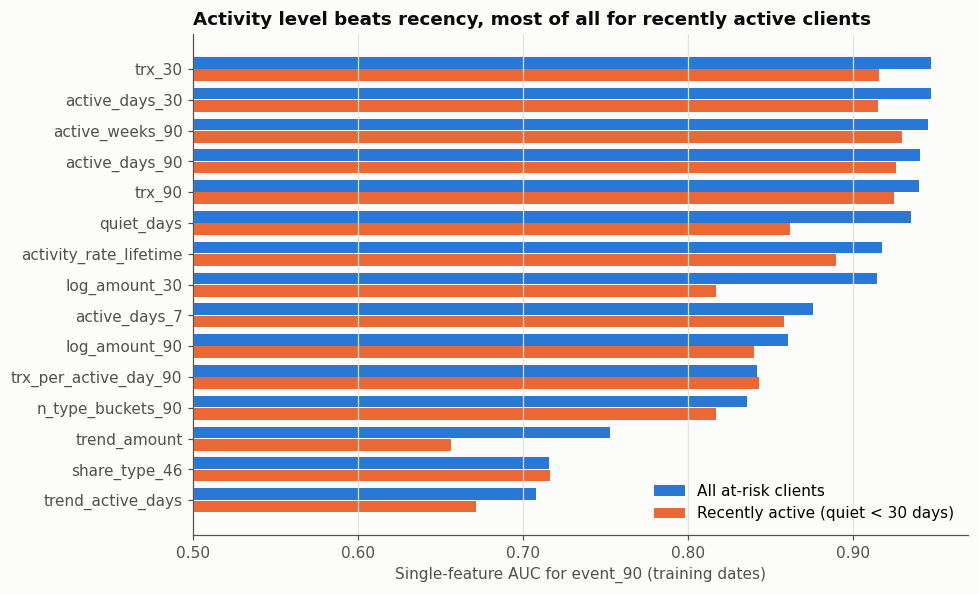

In [114]:
top = signal.head(15).iloc[::-1]
y = np.arange(len(top))
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(y + 0.2, top["all at-risk"] - 0.5, height=0.38, color=BLUE, label="All at-risk clients")
ax.barh(y - 0.2, top["recently active"] - 0.5, height=0.38, color=ORANGE, label="Recently active (quiet < 30 days)")
ax.set_yticks(y, top.index)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v + 0.5:.2f}"))
ax.set_xlabel("Single-feature AUC for event_90 (training dates)")
ax.grid(axis="x", color=GRID)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Activity level beats recency, most of all for recently active clients")
plt.tight_layout()
plt.show()

**Result.** Single features already separate the classes well (AUC up to 0.95)

1. **Activity level beats recency.** Transactions and active days in the last 30 days and
   active weeks (AUC 0.945 to 0.947) edge out `quiet_days` (0.935). Among recently active
   clients the gap widens: `quiet_days` falls to 0.86 while `active_weeks_90` stays at
   0.93. So besides "days quiet", a second rule baseline, **"low activity in the last
   30 days"**, is needed: it is the stronger simple rule.
2. **Trend features are weak on their own** (0.66 to 0.75). Whether they add anything on
   top of levels is for the models and SHAP to show.
3. **ROC-AUC will be high for every model** and will barely separate them. Model
   comparison will rely on PR-AUC, recall in the top-k flagged clients, the Brier score
   and the recently active subgroup.

#### Highly correlated features

Pairs with |correlation| above 0.9 matter for the logistic and Cox baselines (unstable
coefficients), not for gradient boosting.

In [115]:
corr = train.select(core).sample(200_000, seed=1).to_pandas().astype(float).corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("r").reset_index().rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
pairs[pairs["r"].abs() > 0.9].sort_values("r", key=abs, ascending=False)

,feature_a,feature_b,r
199,trx_90,trx_per_active_day_90,0.995732
161,trx_30,trx_90,0.992223
168,trx_30,trx_per_active_day_90,0.987464
135,active_days_90,activity_rate_lifetime,0.976976
97,active_days_30,active_days_90,0.965133
449,trend_active_days,trend_trx,0.960634
104,active_days_30,activity_rate_lifetime,0.940434
65,active_days_7,active_days_30,0.909162


**Result.** Three groups of near-duplicates: transaction counts (`trx_30`, `trx_90`,
`trx_per_active_day_90`, r up to 0.996, largely driven by a few extremely heavy clients),
active days (`active_days_30`, `active_days_90`, `activity_rate_lifetime`), and the two
count trends. LightGBM keeps all of them. The logistic and Cox baselines keep one per
group, after the log transform, to keep coefficients stable and readable.

### Save

In [118]:
FEATURE_DICTIONARY = [
    # name, group, description
    ("quiet_days", "recency", "Days since the last active day, not counting the scoring date"),
    ("tenure_days", "recency", "Days since the client's first transaction"),
    ("activity_rate_lifetime", "recency", "Active days divided by tenure"),
    ("is_new_client", "recency", "Tenure shorter than 90 days"),
    ("active_days_7", "level", "Active days in the last 7 days"),
    ("active_days_30", "level", "Active days in the last 30 days"),
    ("active_days_90", "level", "Active days in the last 90 days"),
    ("active_weeks_90", "level", "Weeks with any activity in the last 90 days (of 13)"),
    ("trx_30", "level", "Transactions in the last 30 days"),
    ("trx_90", "level", "Transactions in the last 90 days"),
    ("trx_per_active_day_90", "level", "Transactions per active day, last 90 days"),
    ("log_amount_30", "level", "log(1 + domestic amount), last 30 days"),
    ("log_amount_90", "level", "log(1 + domestic amount), last 90 days"),
    ("trend_active_days", "trend", "log ratio: active days in last 30 days vs the monthly average of days 31-90"),
    ("trend_trx", "trend", "log ratio: transactions in last 30 days vs the monthly average of days 31-90"),
    ("trend_amount", "trend", "log ratio: domestic amount in last 30 days vs the monthly average of days 31-90"),
    ("max_gap_90", "history", "Longest completed quiet spell starting in the last 90 days"),
    ("past_gaps_30plus", "history", "Completed quiet spells of 30+ days before the scoring date"),
    ("past_gaps_90plus", "history", "Completed quiet spells of 90+ days before the scoring date (past dormancy)"),
    ("n_type_buckets_90", "mix", "Number of the 11 type buckets used in the last 90 days"),
    *[(f"share_type_{k}", "mix", f"Share of last-90-day transactions with event_type {k}") for k in top_types],
    ("share_type_other", "mix", "Share of last-90-day transactions outside the top 10 types"),
    ("dialogs_90", "add-on", "Support dialogues in the last 90 days"),
    ("dialogs_total", "add-on", "Support dialogues before the scoring date"),
    ("days_since_dialog", "add-on", "Days since the last support dialogue (missing if none)"),
    ("geo_available", "add-on", "Scoring date has 90 days of geo history (from Mar 2022)"),
    ("geo_events_90", "add-on", "Geo events in the last 90 days (missing before Mar 2022)"),
    ("geo_days_90", "add-on", "Days with geo events in the last 90 days"),
    ("geo_cells_90", "add-on", "Distinct geohash-5 cells in the last 90 days"),
]
fd = pd.DataFrame(FEATURE_DICTIONARY, columns=["feature", "group", "description"])
assert set(fd["feature"]) == set(feature_cols), set(fd["feature"]) ^ set(feature_cols)
fd.to_csv(PROCESSED / "feature_dictionary.csv", index=False)

panel.write_parquet(PROCESSED / "panel.parquet", compression="zstd")
print(f"wrote panel.parquet: {panel.height:,} rows, {(PROCESSED / 'panel.parquet').stat().st_size / 1e6:,.0f} MB")
print(f"wrote feature_dictionary.csv: {len(fd)} features")
fd.groupby("group", sort=False).size().rename("features").to_frame().T

wrote panel.parquet: 1,538,013 rows, 73 MB
wrote feature_dictionary.csv: 38 features


group,recency,level,trend,history,mix,add-on
features,4,9,3,3,12,7


### Summary

| Output | Contents |
|---|---|
| `data/processed/panel.parquet` | 1,538,013 rows (client × scoring date), 31 core and 7 add-on features, labels, split |
| `data/processed/feature_dictionary.csv` | Name, group and description of every feature |
| `data/interim/daily_activity.parquet` | One row per client per active day (reused by the API later) |

| Check | Result |
|---|---|
| Split gaps | No train or refit outcome window reaches the next set |
| Leakage audit (500 rows) | Features recomputed from raw transactions: 0 mismatches |
| Label audit (500 rows) | Days to event recomputed by walking forward: 0 mismatches |
| Missing values | None in core features; add-on gaps are by design |

### Modelling and evaluation

In [120]:
MODELS = ROOT / "models"
REPORTS = ROOT / "reports"
MODELS.mkdir(exist_ok=True)

In [121]:
HORIZONS = (30, 60, 90)
BUDGET = 0.05            # the bank can contact 5% of at-risk clients each month
SEED = 42

panel = pl.read_parquet(PROCESSED / "panel.parquet").to_pandas()
fd = pd.read_csv(PROCESSED / "feature_dictionary.csv")
CORE = fd.loc[fd["group"] != "add-on", "feature"].tolist()
ADDON = [f for f in fd.loc[fd["group"] == "add-on", "feature"] if f != "geo_available"]
for c in CORE + ADDON:
    panel[c] = panel[c].astype("float32")

train = panel[panel["split"] == "train"].reset_index(drop=True)
valid = panel[panel["split"] == "validation"].reset_index(drop=True)
test = panel[panel["split"] == "test"].reset_index(drop=True)
refit = panel[panel["in_refit"]].reset_index(drop=True)
print(f"core features: {len(CORE)}  add-on features: {len(ADDON)}")
print(f"rows  train {len(train):,}  validation {len(valid):,}  refit {len(refit):,}  test {len(test):,}")

core features: 31  add-on features: 6
rows  train 620,601  validation 247,468  refit 1,029,530  test 340,487


### Evaluation toolkit
**One structural fact shapes the horizons.** To cross 90 quiet days within *h* days, a
client must already be quiet for at least 90 - *h* days, because a new spell cannot reach
90 days inside a shorter window. So within 30 days only clients already quiet 60+ days can
become dormant, and within 60 days only those quiet 30+ days. Recently active clients
therefore **cannot** have a 30- or 60-day event, and those subsets are skipped. Only the
90-day horizon tests whether a model can spot currently active clients who are about to
go quiet.

In [128]:
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

In [129]:
def recall_at_budget(df, score_col, label_col, budget=BUDGET):
    # Share of events captured when flagging the top `budget` share on each scoring date
    out = []
    for _, g in df.groupby("score_date"):
        k = max(1, int(round(budget * len(g))))
        top = g.nlargest(k, score_col)
        out.append(top[label_col].sum() / max(g[label_col].sum(), 1))
    return float(np.mean(out))


def scores(df, prob_col, label_col):
    y, p = df[label_col].to_numpy(), df[prob_col].to_numpy()
    return {
        "PR-AUC": average_precision_score(y, p),
        "recall@5%": recall_at_budget(df, prob_col, label_col),
        "Brier": brier_score_loss(y, p),
        "ROC-AUC": roc_auc_score(y, p),
        "mean predicted": p.mean(),
        "observed": y.mean(),
    }


def evaluate(df, model, horizons=HORIZONS):
    rows = []
    for h in horizons:
        col = f"p{h}"
        if col not in df:
            continue
        for subset, d in [("all", df), ("recently active", df[df["recently_active"]])]:
            if d[f"event_{h}"].nunique() < 2:      # structurally impossible outcome: see section 8
                continue
            rows.append({"model": model, "horizon": h, "subset": subset, **scores(d, col, f"event_{h}")})
    return rows

### Rule baselines

Each rule is turned into a probability with a **lookup table**: the event rate observed in
training for each value of the feature (days quiet 0 to 89; active days in the last 30,
0 to 30). That makes the rules comparable on calibration as well as ranking.

In [130]:
def fit_rule(df, feature):
    table = df.groupby(feature)[[f"event_{h}" for h in HORIZONS]].mean()
    overall = df[[f"event_{h}" for h in HORIZONS]].mean()
    return {"feature": feature, "table": table, "overall": overall}


def predict_rule(rule, df):
    out = pd.DataFrame(index=df.index)
    looked = df[[rule["feature"]]].join(rule["table"], on=rule["feature"])
    for h in HORIZONS:
        out[f"p{h}"] = looked[f"event_{h}"].fillna(rule["overall"][f"event_{h}"]).to_numpy()
    return out


RULES = {"Rule: days quiet": "quiet_days", "Rule: low activity (30d)": "active_days_30"}
val_results = []
val_preds = {}
for name, feat in RULES.items():
    rule = fit_rule(train, feat)
    val_preds[name] = pd.concat([valid, predict_rule(rule, valid)], axis=1)
    val_results += evaluate(val_preds[name], name)
pd.DataFrame(val_results).query("horizon == 90").set_index(["model", "subset"]).drop(columns="horizon")

PR-AUC  recall@5%     Brier  \
model                    subset                                           
Rule: days quiet         all              0.598862   0.476935  0.040154   
                         recently active  0.150212   0.345649  0.025038   
Rule: low activity (30d) all              0.441716   0.382804  0.042993   
                         recently active  0.153144   0.316937  0.024380   

                                           ROC-AUC  mean predicted  observed  
model                    subset                                               
Rule: days quiet         all              0.925222        0.058964  0.068756  
                         recently active  0.853260        0.020259  0.027825  
Rule: low activity (30d) all              0.937128        0.058991  0.068756  
                         recently active  0.903956        0.020708  0.027825

The survival target: time from the scoring date to crossing 90 quiet days, **censored at
90 days** for clients who do not cross within the horizon (administrative censoring).

Linear models need tamer inputs than trees:
log-transformed counts, clipped trends, and one feature from each correlated group. All
inputs are standardised with training means and standard deviations.

In [122]:
import time

In [131]:
COX_FEATURES = ["quiet_days", "tenure_days", "is_new_client", "active_days_30", "active_weeks_90",
                "trx_90", "log_amount_90", "trend_active_days", "trend_amount", "max_gap_90",
                "past_gaps_30plus", "past_gaps_90plus", "n_type_buckets_90",
                "share_type_1", "share_type_46", "share_type_other"]
LOG_COLS = ["quiet_days", "tenure_days", "trx_90", "max_gap_90", "past_gaps_30plus"]
CLIPS = {"trend_active_days": (-3, 3), "trend_amount": (-5, 5)}


def cox_transform(df, stats=None):
    x = df[COX_FEATURES].astype(float).copy()
    for c in LOG_COLS:
        x[c] = np.log1p(x[c])
    for c, (lo, hi) in CLIPS.items():
        x[c] = x[c].clip(lo, hi)
    if stats is None:
        stats = {"mean": x.mean(), "std": x.std()}
    return (x - stats["mean"]) / stats["std"], stats


def fit_cox(df):
    x, stats = cox_transform(df)
    x["T"] = df["days_to_event"].fillna(90).astype(float).to_numpy()
    x["E"] = df["event_90"].astype(int).to_numpy()
    cph = CoxPHFitter(penalizer=0.01).fit(x, "T", "E")
    return cph, stats


def predict_cox(cph, stats, df):
    x, _ = cox_transform(df, stats)
    surv = cph.predict_survival_function(x, times=list(HORIZONS)).T
    return pd.DataFrame({f"p{h}": 1 - surv[h].to_numpy() for h in HORIZONS}, index=df.index)


t0 = time.time()
cph, cox_stats = fit_cox(train)
print(f"fitted in {time.time() - t0:.1f}s")
val_preds["Cox PH"] = pd.concat([valid, predict_cox(cph, cox_stats, valid)], axis=1)
val_results += evaluate(val_preds["Cox PH"], "Cox PH")
cph.summary[["coef", "exp(coef)", "coef lower 95%", "coef upper 95%"]].sort_values("coef")

fitted in 1.2s


,coef,exp(coef),coef lower 95%,coef upper 95%
covariate,,,,
active_weeks_90,-0.610521,0.543068,-0.630931,-0.590110
trx_90,-0.425590,0.653384,-0.447378,-0.403802
active_days_30,-0.240822,0.785982,-0.264102,-0.217542
max_gap_90,-0.203272,0.816056,-0.211794,-0.194750
trend_active_days,-0.141573,0.867992,-0.155405,-0.127741
share_type_46,-0.111068,0.894878,-0.123147,-0.098988
trend_amount,-0.110210,0.895646,-0.120583,-0.099836
log_amount_90,-0.079193,0.923862,-0.089853,-0.068533
past_gaps_30plus,-0.068381,0.933904,-0.080075,-0.056687


**Checking the proportional-hazards assumption.** Cox assumes each feature multiplies the
hazard by the same factor at every time. A Schoenfeld-residual test on a 30,000-row
sample of the training data:

In [125]:
%pip install lifelines

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 4.7 MB/s eta 0:00:0000:010:01
  DEPRECATION: Building 'autograd-gamma' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'autograd-gamma'. Discussion can be found at https://github.com/pypa/pip/issues/6334
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4030 sha256=f6ce56b82c9b7ce95981dabc1bde3f2d1ca8ed3227cb27d31ed0237e9d334bf4
  Stored in directory: /Users/tintin/Library/Caches/pip/wheels/7e/16/46/9477f188924292d3bf1fb8fb42844201591abfc19b7ba6d868
Successfully built autograd-gamma
  Attempting uninstall: pandas
    Found existing installation: pandas 3.1.1
 

In [126]:
from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test
from lifelines.utils import concordance_index

In [132]:
sample = train.sample(30_000, random_state=SEED)
xs, _ = cox_transform(sample, cox_stats)
xs["T"] = sample["days_to_event"].fillna(90).astype(float).to_numpy()
xs["E"] = sample["event_90"].astype(int).to_numpy()
ph = proportional_hazard_test(CoxPHFitter(penalizer=0.01).fit(xs, "T", "E"), xs, time_transform="rank")
ph_table = ph.summary[["test_statistic", "p"]].sort_values("test_statistic", ascending=False)
print(f"features violating proportional hazards at p < 0.01: {(ph_table['p'] < 0.01).sum()} of {len(ph_table)}")
ph_table.head(8)

features violating proportional hazards at p < 0.01: 7 of 16


,test_statistic,p
quiet_days,169.881974,7.851356e-39
max_gap_90,118.632476,1.260482e-27
tenure_days,93.305248,4.482020e-22
past_gaps_30plus,84.299588,4.252038e-20
past_gaps_90plus,55.673630,8.555831e-14
trend_amount,41.810385,1.005679e-10
is_new_client,9.256380,2.346765e-03
share_type_1,5.547623,1.850580e-02


**Result.** The Cox coefficients point the expected way: each standard deviation of
(log) quiet days roughly doubles the hazard, while active weeks, transactions and active
days lower it. But **7 of 16 features break the proportional-hazards assumption**, and
`quiet_days` breaks it most. Recency decides the short horizons
almost on its own, so its effect is not constant over the 90 days.

With 30,000 rows the test flags even small departures, so this alone would not disqualify
Cox. Combined with the clearly worse results below, it is the reason the main model is a
discrete-time hazard model, which lets every effect vary by interval.

### LightGBM discrete-time hazard model

The 90-day horizon is split into three 30-day intervals. Each at-risk row becomes up to
three **person-period rows**, one per interval the client is still "alive" in; the target
is "crosses 90 quiet days in this interval". The interval number `k` is a feature, so
the trees can let any feature's effect change over time: no proportional-hazards
assumption.

From the predicted interval hazards h1, h2, h3:

```latex
P(T \le 30) = h_1, \qquad P(T \le 60) = 1 - (1-h_1)(1-h_2), \qquad P(T \le 90) = 1 - (1-h_1)(1-h_2)(1-h_3)
```

Class weights are deliberately **not** used: they would distort the probabilities, and
the bank's budget is applied by ranking (top 5%), not by a threshold.

In [133]:
def expand(df):
    parts = []
    for k in (1, 2, 3):
        alive = df[(df["interval"] == 0) | (df["interval"] >= k)]
        parts.append(alive.assign(k=np.float32(k), y=(alive["interval"] == k).astype(np.int8)))
    return pd.concat(parts, ignore_index=True)


def predict_hazard(model, df):
    h = {}
    for k in (1, 2, 3):
        x = df[CORE].assign(k=np.float32(k))
        h[k] = model.predict(x[CORE + ["k"]], num_iteration=model.best_iteration or None)
    s30 = 1 - h[1]
    s60 = s30 * (1 - h[2])
    s90 = s60 * (1 - h[3])
    return pd.DataFrame({"p30": 1 - s30, "p60": 1 - s60, "p90": 1 - s90}, index=df.index)


train_pp, valid_pp = expand(train), expand(valid)
print(f"person-period rows: train {len(train_pp):,}  validation {len(valid_pp):,}")
dtrain = lgb.Dataset(train_pp[CORE + ["k"]], train_pp["y"], free_raw_data=False)
dvalid = lgb.Dataset(valid_pp[CORE + ["k"]], valid_pp["y"], reference=dtrain, free_raw_data=False)

person-period rows: train 1,830,546  validation 726,482


**Tuning.** Six settings spanning model size and regularisation. Each trains with early
stopping on the validation person-period log loss; settings are then compared on
validation PR-AUC at 90 days. A small, deliberate grid: on 2 CPUs each fit takes about
half a minute, and the AUC differences between reasonable settings are usually small.

In [134]:
BASE = dict(objective="binary", learning_rate=0.05, bagging_fraction=0.8, bagging_freq=1,
            seed=SEED, num_threads=2, verbose=-1)
PARAM_GRID = [
    dict(num_leaves=15,  min_child_samples=100,  feature_fraction=0.9, lambda_l2=0),
    dict(num_leaves=31,  min_child_samples=200,  feature_fraction=0.8, lambda_l2=0),
    dict(num_leaves=63,  min_child_samples=200,  feature_fraction=0.8, lambda_l2=0),
    dict(num_leaves=63,  min_child_samples=1000, feature_fraction=0.6, lambda_l2=5),
    dict(num_leaves=127, min_child_samples=500,  feature_fraction=0.8, lambda_l2=5),
    dict(num_leaves=255, min_child_samples=1000, feature_fraction=0.7, lambda_l2=10),
]
tuning = []
best = None
for i, params in enumerate(PARAM_GRID):
    t0 = time.time()
    m = lgb.train({**BASE, **params}, dtrain, num_boost_round=3000, valid_sets=[dvalid],
                  callbacks=[lgb.early_stopping(50, verbose=False)])
    pv = pd.concat([valid, predict_hazard(m, valid)], axis=1)
    s_all = scores(pv, "p90", "event_90")
    s_rec = scores(pv[pv["recently_active"]], "p90", "event_90")
    tuning.append({**params, "rounds": m.best_iteration, "val PR-AUC": s_all["PR-AUC"],
                   "val PR-AUC (recent)": s_rec["PR-AUC"], "val Brier": s_all["Brier"],
                   "seconds": round(time.time() - t0)})
    if best is None or s_all["PR-AUC"] > best[0]:
        best = (s_all["PR-AUC"], i, m, pv)
tuning = pd.DataFrame(tuning)
best_i, hazard_model = best[1], best[2]
BEST_PARAMS, BEST_ROUNDS = PARAM_GRID[best_i], hazard_model.best_iteration
val_preds["LightGBM hazard"] = best[3]
val_results += evaluate(best[3], "LightGBM hazard")
print("chosen setting:", BEST_PARAMS, "rounds:", BEST_ROUNDS)
tuning

chosen setting: {'num_leaves': 63, 'min_child_samples': 1000, 'feature_fraction': 0.6, 'lambda_l2': 5} rounds: 200


,num_leaves,min_child_samples,feature_fraction,lambda_l2,rounds,val PR-AUC,val PR-AUC (recent),val Brier,seconds
0,15,100,0.9,0,180,0.673583,0.334570,0.036065,14
1,31,200,0.8,0,165,0.675380,0.337485,0.035996,14
2,63,200,0.8,0,165,0.674887,0.335705,0.036070,16
3,63,1000,0.6,5,200,0.675851,0.338612,0.036046,27
4,127,500,0.8,5,143,0.675059,0.335802,0.036153,20
5,255,1000,0.7,10,138,0.675751,0.342276,0.035987,24


### LightGBM direct classifier (90 days only)

The same features and the chosen settings, trained directly on `event_90`. If it matched
or beat the hazard model at 90 days, the survival framing would only be worth it for
the 30- and 60-day answers.

In [127]:
import lightgbm as lgb

In [135]:
d_tr = lgb.Dataset(train[CORE], train["event_90"].astype(int))
d_va = lgb.Dataset(valid[CORE], valid["event_90"].astype(int), reference=d_tr)
direct_model = lgb.train({**BASE, **BEST_PARAMS}, d_tr, num_boost_round=3000, valid_sets=[d_va],
                         callbacks=[lgb.early_stopping(50, verbose=False)])
DIRECT_ROUNDS = direct_model.best_iteration
val_preds["LightGBM direct"] = valid.assign(p90=direct_model.predict(valid[CORE], num_iteration=DIRECT_ROUNDS))
val_results += evaluate(val_preds["LightGBM direct"], "LightGBM direct")
print("rounds:", DIRECT_ROUNDS)

rounds: 111


### Validation results

In [136]:
MODEL_ORDER = ["Rule: days quiet", "Rule: low activity (30d)", "Cox PH", "LightGBM direct", "LightGBM hazard"]
val_df = pd.DataFrame(val_results)
(val_df.query("horizon == 90")
 .pivot_table(index="model", columns="subset", values=["PR-AUC", "recall@5%", "Brier", "ROC-AUC"])
 .reindex(MODEL_ORDER))

Brier                    PR-AUC                  \
subset                         all recently active       all recently active   
model                                                                          
Rule: days quiet          0.040154        0.025038  0.598862        0.150212   
Rule: low activity (30d)  0.042993        0.024380  0.441716        0.153144   
Cox PH                    0.038042        0.022844  0.628104        0.294271   
LightGBM direct           0.035898        0.021834  0.676748        0.343632   
LightGBM hazard           0.036046        0.021902  0.675851        0.338612   

                           ROC-AUC                 recall@5%                  
subset                         all recently active       all recently active  
model                                                                         
Rule: days quiet          0.925222        0.853260  0.476935        0.345649  
Rule: low activity (30d)  0.937128        0.903956  0.382804        0.316937  
Cox PH                    0.954314        0.930909  0.494191        0.509331  
LightGBM direct           0.961136        0.943790  0.510364        0.557955  
LightGBM hazard           0.961207        0.944010  0.507672        0.557104

**Result.** On the validation dates:

- **The two LightGBM models lead** and are almost tied (PR-AUC 0.676 to 0.677 overall,
  0.34 for recently active clients).
- **Cox is clearly behind** overall (0.63) and for recently active clients (0.29).
- **The rules collapse for recently active clients** (PR-AUC 0.15), less than half the
  boosted models.
- The low-activity rule has the higher ROC-AUC (0.937 against 0.925), but days quiet wins clearly on PR-AUC (0.60 against 0.44)
  and recall. Ranking the bulk of clients well is not the same as finding the riskiest few.

Tuning hardly mattered: all six LightGBM settings land within 0.003 PR-AUC of each other,
so a larger search would not change the conclusions.

### Refit and score the test dates

Every model is refit with its chosen setup on all dates up to April 2022 (1.03M rows), then
predicts the four test dates. LightGBM uses the number of rounds found by early stopping.

In [137]:
test_preds = {}
for name, feat in RULES.items():
    test_preds[name] = pd.concat([test, predict_rule(fit_rule(refit, feat), test)], axis=1)

cph_final, cox_stats_final = fit_cox(refit)
test_preds["Cox PH"] = pd.concat([test, predict_cox(cph_final, cox_stats_final, test)], axis=1)

refit_pp = expand(refit)
hazard_final = lgb.train({**BASE, **BEST_PARAMS}, lgb.Dataset(refit_pp[CORE + ["k"]], refit_pp["y"]),
                         num_boost_round=BEST_ROUNDS)
test_preds["LightGBM hazard"] = pd.concat([test, predict_hazard(hazard_final, test)], axis=1)

direct_final = lgb.train({**BASE, **BEST_PARAMS}, lgb.Dataset(refit[CORE], refit["event_90"].astype(int)),
                         num_boost_round=DIRECT_ROUNDS)
test_preds["LightGBM direct"] = test.assign(p90=direct_final.predict(test[CORE]))
del refit_pp

test_results = pd.DataFrame(sum((evaluate(test_preds[m], m) for m in MODEL_ORDER), []))
headline = (test_results.query("horizon == 90")
            .pivot_table(index="model", columns="subset",
                         values=["PR-AUC", "recall@5%", "Brier", "mean predicted", "observed"])
            .reindex(MODEL_ORDER))
ceiling = np.mean([min(1.0, max(1, round(BUDGET * len(g))) / g["event_90"].sum()) for _, g in test.groupby("score_date")])
print(f"highest recall any model could reach at a 5% budget on test dates (all at-risk): {ceiling:.0%}")
headline

highest recall any model could reach at a 5% budget on test dates (all at-risk): 61%


Brier                    PR-AUC                  \
subset                         all recently active       all recently active   
model                                                                          
Rule: days quiet          0.043631        0.027740  0.665576        0.168748   
Rule: low activity (30d)  0.047527        0.027212  0.504772        0.160027   
Cox PH                    0.041492        0.025149  0.677954        0.307477   
LightGBM direct           0.037743        0.023677  0.735108        0.357746   
LightGBM hazard           0.037605        0.023597  0.736014        0.359856   

                         mean predicted                  observed  \
subset                              all recently active       all   
model                                                               
Rule: days quiet               0.067954        0.022288  0.082382   
Rule: low activity (30d)       0.066294        0.022786  0.082382   
Cox PH                         0.073740        0.024690  0.082382   
LightGBM direct                0.075750        0.027907  0.082382   
LightGBM hazard                0.076264        0.028086  0.082382   

                                         recall@5%                  
subset                   recently active       all recently active  
model                                                               
Rule: days quiet                0.031208  0.459669        0.340535  
Rule: low activity (30d)        0.031208  0.359662        0.299100  
Cox PH                          0.031208  0.456958        0.485788  
LightGBM direct                 0.031208  0.480064        0.543049  
LightGBM hazard                 0.031208  0.481628        0.544547

**Result.** At the 90-day horizon on the four test dates:

| Model | PR-AUC (all) | PR-AUC (recently active) | Recall at 5% (recently active) |
|---|---|---|---|
| Rule: days quiet | 0.666 | 0.169 | 34% |
| Cox PH | 0.678 | 0.308 | 49% |
| **LightGBM hazard** | **0.736** | **0.360** | **55%** |

The test numbers are higher than validation for every model, because the base rate is
higher (8.2% against 6.9%) and PR-AUC rises with the base rate. The ordering is the same
as on validation, which is what matters.

Overall, recall at a 5% budget barely separates the models (46 to 48%). The ceiling is low
because 8.2% of clients go dormant but only 5% are contacted (see the printed limit
above). The model's advantage is concentrated where the brief said early warning
matters: among recently active clients it reaches **55% of next-quarter dormancies
against 34% for the days-quiet rule**.

### Are the differences real? Client-level bootstrap

The same clients appear on several test dates, so rows are not independent. The bootstrap
resamples **clients** (with all their rows), 200 times, and recomputes the PR-AUC gap
between the hazard model and the best rule.

In [138]:
def bootstrap_gap(df_a, df_b, label="event_90", col="p90", reps=200, seed=SEED):
    clients = df_a["client_key"].to_numpy()
    uniq, inv = np.unique(clients, return_inverse=True)
    rng = np.random.default_rng(seed)
    y = df_a[label].to_numpy()
    gaps = []
    for _ in range(reps):
        w = np.bincount(rng.integers(0, len(uniq), len(uniq)), minlength=len(uniq))[inv]
        gaps.append(average_precision_score(y, df_a[col], sample_weight=w)
                    - average_precision_score(y, df_b[col], sample_weight=w))
    return np.mean(gaps), np.percentile(gaps, [2.5, 97.5])


best_rule = max(RULES, key=lambda m: test_results.query("model == @m and horizon == 90 and subset == 'all'")["PR-AUC"].iloc[0])
rows = []
for subset in ("all", "recently active"):
    mask = slice(None) if subset == "all" else test["recently_active"].to_numpy()
    for other in (best_rule, "Cox PH", "LightGBM direct"):
        a = test_preds["LightGBM hazard"].loc[mask]
        b = test_preds[other].loc[mask]
        gap, (lo, hi) = bootstrap_gap(a, b)
        rows.append({"subset": subset, "hazard model minus": other, "PR-AUC gap": gap, "95% CI low": lo, "95% CI high": hi})
pd.DataFrame(rows)

,subset,hazard model minus,PR-AUC gap,95% CI low,95% CI high
0,all,Rule: days quiet,0.070645,0.068041,0.073476
1,all,Cox PH,0.057875,0.053413,0.062082
2,all,LightGBM direct,0.000875,0.000158,0.001564
3,recently active,Rule: days quiet,0.190784,0.181184,0.199705
4,recently active,Cox PH,0.052050,0.044976,0.059713
5,recently active,LightGBM direct,0.002080,-0.000032,0.004205


**Result.** The hazard model's lead over the days-quiet rule (+0.07 PR-AUC overall,
+0.19 for recently active) and over Cox (+0.05 to +0.06) is far outside the bootstrap
noise. Against the direct LightGBM classifier the gap is **under 0.002** and, for
recently active clients, the interval includes zero: **the two are equivalent at 90 days.**

So the survival framing costs nothing in accuracy and adds the 30- and 60-day answers
from one model. That, not a higher score, is the reason to keep it.

The 30-day results look excellent for every model, including the days-quiet rule (PR-AUC
0.91). A 30-day event is only possible for
clients already quiet for 60+ days, so the answer is mostly decided by recency. The
60-day horizon is partly in the same position. **The 90-day horizon is the real test.**

The mean of the Brier scores at 30, 60 and 90 days stands in for the integrated Brier
score from the proposal. Because nothing is censored before 90 days, no inverse
probability of censoring weights are needed.

### What the bank gets: recall at each contact budget

In [140]:
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

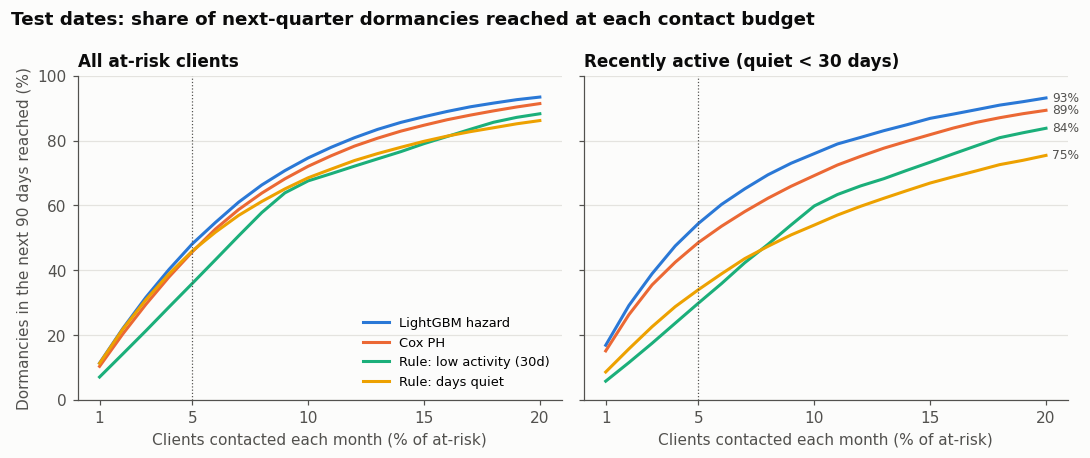

In [141]:
budgets = np.arange(0.01, 0.205, 0.01)
show = [("LightGBM hazard", BLUE), ("Cox PH", ORANGE), ("Rule: low activity (30d)", AQUA), ("Rule: days quiet", YELLOW)]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, (title, sel) in zip(axes, [("All at-risk clients", None), ("Recently active (quiet < 30 days)", "recent")]):
    for name, color in show:
        d = test_preds[name] if sel is None else test_preds[name][test_preds[name]["recently_active"]]
        curve = [recall_at_budget(d, "p90", "event_90", b) * 100 for b in budgets]
        ax.plot(budgets * 100, curve, color=color, lw=2, label=name)
        if sel == "recent":   # end labels only where the lines are far enough apart to read
            ax.annotate(f"{curve[-1]:.0f}%", (budgets[-1] * 100, curve[-1]), xytext=(4, 0),
                        textcoords="offset points", va="center", color=INK_2, fontsize=8)
    ax.axvline(BUDGET * 100, color=INK_2, lw=0.8, ls=":")
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Clients contacted each month (% of at-risk)")
    ax.set_xticks([1, 5, 10, 15, 20])
    ax.set_ylim(0, 100)
axes[0].set_ylabel("Dormancies in the next 90 days reached (%)")
axes[0].legend(loc="lower right", fontsize=8.5)
fig.suptitle("Test dates: share of next-quarter dormancies reached at each contact budget",
             x=0.01, ha="left", fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

**Result.** For all at-risk clients the curves almost overlap at small budgets: the
riskiest clients are those already quiet for a long time, and every method finds them.
For **recently active clients** the gap is wide at every budget: at 5% the hazard model
reaches 55% of next-quarter dormancies, Cox 49%, the days-quiet rule 34% and the
low-activity rule 30%. To reach the same share with the days-quiet rule, the bank would
have to contact about twice as many clients.

### Calibration and drift

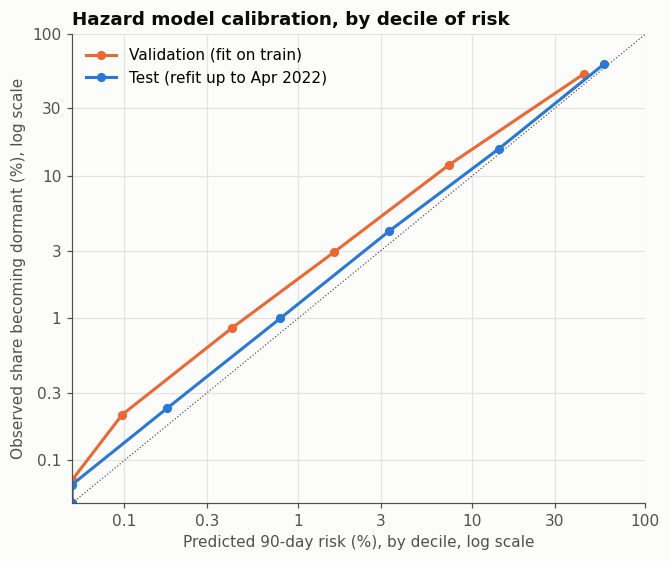

,mean predicted,observed,observed / predicted
validation,0.053963,0.068756,1.274127
test,0.076264,0.082382,1.080222


In [142]:
def calibration_points(d, col="p90", label="event_90", bins=10):
    q = pd.qcut(d[col].rank(method="first"), bins, labels=False)   # rank first: many tied low scores
    g = d.groupby(q).agg(pred=(col, "mean"), obs=(label, "mean"))
    return g


val_cal = calibration_points(val_preds["LightGBM hazard"]).clip(lower=0.0005)
test_cal = calibration_points(test_preds["LightGBM hazard"]).clip(lower=0.0005)
fig, ax = plt.subplots(figsize=(6.2, 5.2))
# Log axes: most clients have very low risk, so on linear axes six deciles overlap near zero
lo, hi = 0.05, 100
ax.plot([lo, hi], [lo, hi], color=INK_2, lw=0.8, ls=":")
ax.plot(val_cal["pred"] * 100, val_cal["obs"] * 100, color=ORANGE, lw=2, marker="o", ms=5, label="Validation (fit on train)")
ax.plot(test_cal["pred"] * 100, test_cal["obs"] * 100, color=BLUE, lw=2, marker="o", ms=5, label="Test (refit up to Apr 2022)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ticks = [0.1, 0.3, 1, 3, 10, 30, 100]
ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
ax.set_yticks(ticks, [f"{t:g}" for t in ticks])
ax.minorticks_off()
ax.set_xlabel("Predicted 90-day risk (%), by decile, log scale")
ax.set_ylabel("Observed share becoming dormant (%), log scale")
ax.grid(axis="x", color=GRID)
ax.legend(loc="upper left")
ax.set_title("Hazard model calibration, by decile of risk")
plt.tight_layout()
plt.show()

cal = pd.DataFrame({
    "mean predicted": [val_preds["LightGBM hazard"]["p90"].mean(), test_preds["LightGBM hazard"]["p90"].mean()],
    "observed": [valid["event_90"].mean(), test["event_90"].mean()]}, index=["validation", "test"])
cal["observed / predicted"] = cal["observed"] / cal["mean predicted"]
cal

**Result.** The model **under-predicts** risk on dates later than its training data,
because of the upward drift in the event rate:

- Fitted on 2021 only, it under-predicts the validation dates by about 28% overall
  (observed / predicted = 1.28).
- Refitted with dates up to April 2022, the gap on the test dates shrinks to about 8%
  (1.08), and the deciles sit close to the diagonal.

The lowest-risk deciles predict and show under 0.05% risk, so they sit at the bottom-left
corner of the log-scale chart.

The ranking, and so the contact list, is not affected; the probability level is. In
production this calls for **monitoring the predicted against the observed rate and
refitting regularly** on the latest labelled dates

### What drives the hazard model?

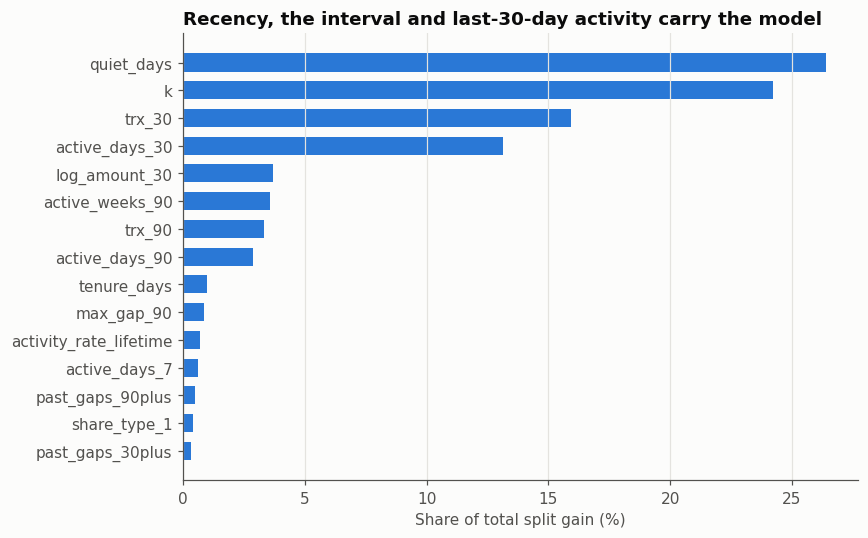

gain share by group:


level       43.4%
recency     28.1%
interval    24.2%
mix          2.0%
history      1.7%
trend        0.6%
dtype: str

In [143]:
imp = (pd.Series(hazard_final.feature_importance("gain"), index=hazard_final.feature_name())
       .sort_values(ascending=False))
imp_share = imp / imp.sum()
top = imp_share.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(range(len(top)), top * 100, color=BLUE, height=0.65)
ax.set_yticks(range(len(top)), top.index)
ax.set_xlabel("Share of total split gain (%)")
ax.grid(axis="x", color=GRID)
ax.grid(axis="y", visible=False)
ax.set_title("Recency, the interval and last-30-day activity carry the model")
plt.tight_layout()
plt.show()
print("gain share by group:")
groups = fd.set_index("feature")["group"].to_dict() | {"k": "interval"}
imp_share.groupby(imp_share.index.map(groups)).sum().sort_values(ascending=False).map("{:.1%}".format)

**Result.** Activity levels (43% of gain), recency (28%) and the interval `k` (24%)
carry the model; transaction mix and pausing history add about 2% each and the trend
features 0.6%.

The fade before dormancy is real, but once the model has activity in the
last 30 days *and* the last 90 days, it can form that contrast itself, so the explicit
trend features add little. That is worth reporting as a finding rather than hiding.

Gain importance shows *where the trees split*, not the direction or size of each
feature's effect on a given client.

### Do geo and dialogue features help?

Geo history exists only from March 2022. The fair test: two LightGBM direct
classifiers trained on the **same rows**, the two validation dates that have geo
(March and April 2022), one with core features and one with core plus add-on features,
both scored on the test dates.

**Result.** Geo and dialogue features add **nothing measurable**: the PR-AUC gap is -0.0003
overall and +0.002 for recently active clients, with both bootstrap intervals including
zero.

*Caveat:* this test trains on only two scoring dates, the only ones with geo history
before the test period, so a small benefit could be hidden. The decision is still clear
for deployment: the served model uses **core transaction features only**, which also
keeps the API independent of the geo and dialogue feeds.

### Save the models and results

In [144]:

import joblib

In [146]:
import json

In [148]:
hazard_final.save_model(MODELS / "lgbm_hazard.txt")
direct_final.save_model(MODELS / "lgbm_direct_90d.txt")
# lifelines keeps a copy of the training data inside the fitted model (over 100 MB), so
# only what prediction needs is saved: coefficients, centring, baseline survival.
cox_light = {
    "features": COX_FEATURES, "log_cols": LOG_COLS, "clips": CLIPS,
    "mean": cox_stats_final["mean"].to_dict(), "std": cox_stats_final["std"].to_dict(),
    "coef": cph_final.params_.to_dict(), "norm_mean": cph_final._norm_mean.to_dict(),
    "baseline_survival": {h: float(cph_final.baseline_survival_.loc[:h].iloc[-1, 0]) for h in HORIZONS},
}


def predict_cox_light(m, df):
    x, _ = cox_transform(df, {"mean": pd.Series(m["mean"]), "std": pd.Series(m["std"])})
    lin = ((x - pd.Series(m["norm_mean"])) * pd.Series(m["coef"])).sum(axis=1).to_numpy()
    return pd.DataFrame({f"p{h}": 1 - m["baseline_survival"][h] ** np.exp(lin) for h in HORIZONS}, index=df.index)


check = predict_cox_light(cox_light, test)
assert np.allclose(check.to_numpy(), test_preds["Cox PH"][["p30", "p60", "p90"]].to_numpy(), atol=1e-6)
joblib.dump(cox_light, MODELS / "cox_ph.joblib")
joblib.dump({name: fit_rule(refit, feat) for name, feat in RULES.items()}, MODELS / "rules.joblib")

metadata = {
    "dormancy_window_days": 90,
    "horizons_days": list(HORIZONS),
    "lookback_days": 90,
    "features": CORE,
    "top_event_types": [int(c.split("_")[-1]) for c in CORE if c.startswith("share_type_") and c != "share_type_other"],
    "domestic_currency": 11,
    "hazard_params": {**BASE, **BEST_PARAMS},
    "hazard_rounds": int(BEST_ROUNDS),
    "refit_dates": sorted(refit["score_date"].astype(str).unique().tolist()),
    "test_dates": sorted(test["score_date"].astype(str).unique().tolist()),
    "test_metrics_90d": headline.loc["LightGBM hazard"].unstack(0).to_dict(),
}
(MODELS / "metadata.json").write_text(json.dumps(metadata, indent=2, default=float))
test_results.to_csv(REPORTS / "test_results.csv", index=False)
tuning.to_csv(REPORTS / "tuning_results.csv", index=False)
print("saved:")
!ls -lh {MODELS} {REPORTS}/*.csv

saved:
zsh:1: no matches found: Project/084045_dsa_8401_capstone_project/reports/*.csv


### Summary

**Chosen model: LightGBM discrete-time hazard** (63 leaves, at least 1,000 rows per leaf,
60% of features per tree, L2 = 5, 218 rounds), refit on all dates up to April 2022.

| Test dates, 90-day horizon | All at-risk | Recently active |
|---|---|---|
| PR-AUC | 0.736 (rule 0.666, Cox 0.678) | 0.360 (rule 0.169, Cox 0.308) |
| Recall at a 5% contact budget | 48% (rule 46%) | 55% (rule 34%) |
| Brier score | 0.0376 (rule 0.0436) | 0.0236 (rule 0.0277) |
| Mean predicted vs observed | 7.6% vs 8.2% | 2.8% vs 3.1% |

**Justification, in one line each**

- *Over the rules:* doubles PR-AUC and reaches 1.6 times as many dormancies among
  recently active clients, where early warning is worth most.
- *Over Cox:* better on every metric, and it does not need proportional hazards, which
  7 of 16 features violate.
- *Over the direct classifier:* equal at 90 days, and it adds 30- and 60-day risk from the
  same model.
- *Not used:* class weights (would distort the probabilities that the bank reads);
  a GRU on raw event sequences (the stretch goal: tabular boosting already captures the
  activity signal, and with 2 CPUs the cost is not justified by the expected gain);
  geo and dialogue features (no measurable gain).

**Limitations to report**

- The 30- and 60-day horizons are largely decided by recency: a client must already be
  quiet 60+ or 30+ days to cross within them.
- Probabilities drift low as the event rate rises; regular refits and monitoring are needed.
- The label marks crossing the bank's 90-day threshold; half of those clients transact
  again later.
- Corporate clients of one non-Kenyan bank: the method transfers, the numbers may not.

**Saved:** `models/lgbm_hazard.txt` (served model), `lgbm_direct_90d.txt`, `cox_ph.joblib`,
`rules.joblib`, `metadata.json`; `reports/test_results.csv`, `tuning_results.csv`.